In [1]:
#import statements
import pandas as pd
from flatbuffers.packer import int64
import seaborn as sns
import matplotlib.pyplot as plt

In [26]:
#read in combined property dataset csv
combinedProperty_df = pd.read_csv("combinedPropertyDataset.csv")

In [32]:
combinedProperty_df.columns

Index(['FREQUENCY', 'PERIOD BEGIN', 'PERIOD END', 'REGION NAME',
       'PROPERTY TYPE', 'INCOME GROUP', 'DOWN PAYMENT PERCENT (%)',
       'INCOME REQUIRED ($)', 'INCOME REQUIRED YOY (%)',
       'SHARE OF INCOME ON HOUSING (%)',
       'SHARE OF INCOME ON HOUSING YOY (PPTS)', 'AFFORDABLE LISTING SHARE (%)',
       'AFFORDABLE LISTING SHARE YOY (PPTS)', 'YEARS TO SAVE DOWN PAYMENT',
       'YEARS TO SAVE DOWN PAYMENT YOY (%)', 'MONTHLY HOUSING PAYMENT ($)',
       'MONTHLY MORTGAGE PAYMENT ($)', 'MONTHLY PROPERTY TAX ($)',
       'MONTHLY PROPERTY INSURANCE ($)', 'MONTHLY PMI ($)',
       'DOWN PAYMENT AMOUNT ($)', 'MEDIAN HOUSEHOLD INCOME ($)',
       'MEDIAN SALE PRICE ($)', 'MEDIAN SALE PRICE YOY (%)', 'HOMES SOLD',
       'HOMES SOLD YOY (%)', 'Year', 'Month', 'Month Name', 'Quarter',
       'DOWN PAYMENT AMOUNT ($) Prop', 'INCOME REQUIRED YOY (%) Prop',
       'SHARE OF INCOME ON HOUSING (%) Prop',
       'SHARE OF INCOME ON HOUSING YOY (PPTS) Prop',
       'AFFORDABLE LISTING SH

In [3]:
combinedProperty_df.shape

(43260, 42)

In [4]:
combinedProperty_df.head()

,FREQUENCY,PERIOD BEGIN,PERIOD END,REGION NAME,PROPERTY TYPE,INCOME GROUP,DOWN PAYMENT PERCENT (%),INCOME REQUIRED ($),INCOME REQUIRED YOY (%),SHARE OF INCOME ON HOUSING (%),...,SHARE OF INCOME ON HOUSING (%) Prop,SHARE OF INCOME ON HOUSING YOY (PPTS) Prop,AFFORDABLE LISTING SHARE (%) Prop,AFFORDABLE LISTING SHARE YOY (PPTS) Prop,YEARS TO SAVE DOWN PAYMENT YOY (%) Prop,MEDIAN SALE PRICE YOY (%) Prop,HOMES SOLD YOY (%) Prop,Season,Year-Month,Period Length (Days)
0,Monthly,2026-06-01,2026-06-30,Alabama,Single Family,Homeowner,3.5,90532.0,-1.49,31.52,...,0.3152,-0.0181,0.4057,0.0287,-0.0276,0.0130,0.0832,Summer,2026-06,30
1,Monthly,2026-05-01,2026-05-31,Alabama,Single Family,Homeowner,3.5,90652.0,-0.56,31.56,...,0.3156,-0.0150,0.4212,0.0419,-0.0142,0.0269,0.0091,Spring,2026-05,31
2,Monthly,2026-04-01,2026-04-30,Alabama,Single Family,Homeowner,3.5,88160.0,0.65,30.69,...,0.3069,-0.0107,0.4302,0.0365,-0.0003,0.0413,0.0217,Spring,2026-04,30
3,Monthly,2026-03-01,2026-03-31,Alabama,Single Family,Homeowner,3.5,86472.0,-1.26,30.11,...,0.3011,-0.0165,0.4482,0.0405,-0.0133,0.0279,0.0641,Spring,2026-03,31
4,Monthly,2026-02-01,2026-02-28,Alabama,Single Family,Homeowner,3.5,82901.0,-3.96,28.86,...,0.2886,-0.0244,0.4824,0.0765,-0.0137,0.0274,0.0637,Winter,2026-02,28


In [5]:
combinedProperty_df.tail()

,FREQUENCY,PERIOD BEGIN,PERIOD END,REGION NAME,PROPERTY TYPE,INCOME GROUP,DOWN PAYMENT PERCENT (%),INCOME REQUIRED ($),INCOME REQUIRED YOY (%),SHARE OF INCOME ON HOUSING (%),...,SHARE OF INCOME ON HOUSING (%) Prop,SHARE OF INCOME ON HOUSING YOY (PPTS) Prop,AFFORDABLE LISTING SHARE (%) Prop,AFFORDABLE LISTING SHARE YOY (PPTS) Prop,YEARS TO SAVE DOWN PAYMENT YOY (%) Prop,MEDIAN SALE PRICE YOY (%) Prop,HOMES SOLD YOY (%) Prop,Season,Year-Month,Period Length (Days)
43255,Monthly,2023-05-01,2023-05-31,Wyoming,Starter Home,Homeowner,20.0,52048.0,30.61,17.36,...,0.1736,0.0374,0.9330,-0.0565,0.1428,0.1707,-0.0452,Spring,2023-05,30
43256,Monthly,2023-04-01,2023-04-30,Wyoming,Starter Home,Homeowner,20.0,50965.0,31.95,17.00,...,0.1700,0.0380,0.9558,-0.0413,0.1366,0.1644,-0.0984,Spring,2023-04,29
43257,Monthly,2023-03-01,2023-03-31,Wyoming,Starter Home,Homeowner,20.0,51518.0,44.78,17.18,...,0.1718,0.0502,0.9558,-0.0365,0.1322,0.1599,-0.2097,Spring,2023-03,30
43258,Monthly,2023-02-01,2023-02-28,Wyoming,Starter Home,Homeowner,20.0,49399.0,44.26,16.48,...,0.1648,0.0478,0.9704,-0.0209,0.1108,0.1379,-0.2932,Winter,2023-02,27
43259,Monthly,2023-01-01,2023-01-31,Wyoming,Starter Home,Homeowner,20.0,48995.0,47.05,16.34,...,0.1634,0.0496,0.9719,-0.0194,0.0964,0.1232,-0.3612,Winter,2023-01,30


In [6]:
combinedProperty_df.dtypes

FREQUENCY                                      object
PERIOD BEGIN                                   object
PERIOD END                                     object
REGION NAME                                    object
PROPERTY TYPE                                  object
INCOME GROUP                                   object
DOWN PAYMENT PERCENT (%)                      float64
INCOME REQUIRED ($)                           float64
INCOME REQUIRED YOY (%)                       float64
SHARE OF INCOME ON HOUSING (%)                float64
SHARE OF INCOME ON HOUSING YOY (PPTS)         float64
AFFORDABLE LISTING SHARE (%)                  float64
AFFORDABLE LISTING SHARE YOY (PPTS)           float64
YEARS TO SAVE DOWN PAYMENT                    float64
YEARS TO SAVE DOWN PAYMENT YOY (%)            float64
MONTHLY HOUSING PAYMENT ($)                   float64
MONTHLY MORTGAGE PAYMENT ($)                  float64
MONTHLY PROPERTY TAX ($)                      float64
MONTHLY PROPERTY INSURANCE (

In [7]:
#converting 'Period Begin' and 'Period End' to pandas datetime objects:
combinedProperty_df['PERIOD BEGIN'] = pd.to_datetime(combinedProperty_df['PERIOD BEGIN'])
combinedProperty_df['PERIOD END'] = pd.to_datetime(combinedProperty_df['PERIOD END'])

In [8]:
combinedProperty_df.dtypes


FREQUENCY                                             object
PERIOD BEGIN                                  datetime64[ns]
PERIOD END                                    datetime64[ns]
REGION NAME                                           object
PROPERTY TYPE                                         object
INCOME GROUP                                          object
DOWN PAYMENT PERCENT (%)                             float64
INCOME REQUIRED ($)                                  float64
INCOME REQUIRED YOY (%)                              float64
SHARE OF INCOME ON HOUSING (%)                       float64
SHARE OF INCOME ON HOUSING YOY (PPTS)                float64
AFFORDABLE LISTING SHARE (%)                         float64
AFFORDABLE LISTING SHARE YOY (PPTS)                  float64
YEARS TO SAVE DOWN PAYMENT                           float64
YEARS TO SAVE DOWN PAYMENT YOY (%)                   float64
MONTHLY HOUSING PAYMENT ($)                          float64
MONTHLY MORTGAGE PAYMENT

In [10]:
print(combinedProperty_df.columns.tolist())

['FREQUENCY', 'PERIOD BEGIN', 'PERIOD END', 'REGION NAME', 'PROPERTY TYPE', 'INCOME GROUP', 'DOWN PAYMENT PERCENT (%)', 'INCOME REQUIRED ($)', 'INCOME REQUIRED YOY (%)', 'SHARE OF INCOME ON HOUSING (%)', 'SHARE OF INCOME ON HOUSING YOY (PPTS)', 'AFFORDABLE LISTING SHARE (%)', 'AFFORDABLE LISTING SHARE YOY (PPTS)', 'YEARS TO SAVE DOWN PAYMENT', 'YEARS TO SAVE DOWN PAYMENT YOY (%)', 'MONTHLY HOUSING PAYMENT ($)', 'MONTHLY MORTGAGE PAYMENT ($)', 'MONTHLY PROPERTY TAX ($)', 'MONTHLY PROPERTY INSURANCE ($)', 'MONTHLY PMI ($)', 'DOWN PAYMENT AMOUNT ($)', 'MEDIAN HOUSEHOLD INCOME ($)', 'MEDIAN SALE PRICE ($)', 'MEDIAN SALE PRICE YOY (%)', 'HOMES SOLD', 'HOMES SOLD YOY (%)', 'Year', 'Month', 'Month Name', 'Quarter', 'DOWN PAYMENT AMOUNT ($) Prop', 'INCOME REQUIRED YOY (%) Prop', 'SHARE OF INCOME ON HOUSING (%) Prop', 'SHARE OF INCOME ON HOUSING YOY (PPTS) Prop', 'AFFORDABLE LISTING SHARE (%) Prop', 'AFFORDABLE LISTING SHARE YOY (PPTS) Prop', 'YEARS TO SAVE DOWN PAYMENT YOY (%) Prop', 'MEDIAN S

In [11]:
combinedProperty_df['PROPERTY TYPE'].isna().sum()

np.int64(0)

In [12]:
combinedProperty_df[['FREQUENCY', 'PERIOD BEGIN', 'PERIOD END', 'REGION NAME', 'PROPERTY TYPE', 'INCOME GROUP', 'DOWN PAYMENT PERCENT (%)', 'INCOME REQUIRED ($)', 'INCOME REQUIRED YOY (%)', 'SHARE OF INCOME ON HOUSING (%)', 'SHARE OF INCOME ON HOUSING YOY (PPTS)', 'AFFORDABLE LISTING SHARE (%)', 'AFFORDABLE LISTING SHARE YOY (PPTS)', 'YEARS TO SAVE DOWN PAYMENT', 'YEARS TO SAVE DOWN PAYMENT YOY (%)', 'MONTHLY HOUSING PAYMENT ($)', 'MONTHLY MORTGAGE PAYMENT ($)', 'MONTHLY PROPERTY TAX ($)', 'MONTHLY PROPERTY INSURANCE ($)', 'MONTHLY PMI ($)', 'DOWN PAYMENT AMOUNT ($)', 'MEDIAN HOUSEHOLD INCOME ($)', 'MEDIAN SALE PRICE ($)', 'MEDIAN SALE PRICE YOY (%)', 'HOMES SOLD', 'HOMES SOLD YOY (%)', 'Year', 'Month', 'Month Name', 'Quarter', 'DOWN PAYMENT AMOUNT ($) Prop', 'INCOME REQUIRED YOY (%) Prop', 'SHARE OF INCOME ON HOUSING (%) Prop', 'SHARE OF INCOME ON HOUSING YOY (PPTS) Prop', 'AFFORDABLE LISTING SHARE (%) Prop', 'AFFORDABLE LISTING SHARE YOY (PPTS) Prop', 'YEARS TO SAVE DOWN PAYMENT YOY (%) Prop', 'MEDIAN SALE PRICE YOY (%) Prop', 'HOMES SOLD YOY (%) Prop', 'Season', 'Year-Month', 'Period Length (Days)']].isna().sum()

FREQUENCY                                        0
PERIOD BEGIN                                     0
PERIOD END                                       0
REGION NAME                                      0
PROPERTY TYPE                                    0
INCOME GROUP                                     0
DOWN PAYMENT PERCENT (%)                         0
INCOME REQUIRED ($)                            945
INCOME REQUIRED YOY (%)                       1075
SHARE OF INCOME ON HOUSING (%)                 945
SHARE OF INCOME ON HOUSING YOY (PPTS)         1075
AFFORDABLE LISTING SHARE (%)                   625
AFFORDABLE LISTING SHARE YOY (PPTS)            735
YEARS TO SAVE DOWN PAYMENT                     945
YEARS TO SAVE DOWN PAYMENT YOY (%)            1075
MONTHLY HOUSING PAYMENT ($)                    945
MONTHLY MORTGAGE PAYMENT ($)                   945
MONTHLY PROPERTY TAX ($)                       945
MONTHLY PROPERTY INSURANCE ($)                 945
MONTHLY PMI ($)                

In [13]:
combinedProperty_df.isna().groupby(combinedProperty_df['PROPERTY TYPE'])[['FREQUENCY', 'PERIOD BEGIN', 'PERIOD END', 'REGION NAME', 'INCOME GROUP', 'DOWN PAYMENT PERCENT (%)', 'INCOME REQUIRED ($)', 'INCOME REQUIRED YOY (%)', 'SHARE OF INCOME ON HOUSING (%)', 'SHARE OF INCOME ON HOUSING YOY (PPTS)', 'AFFORDABLE LISTING SHARE (%)', 'AFFORDABLE LISTING SHARE YOY (PPTS)', 'YEARS TO SAVE DOWN PAYMENT', 'YEARS TO SAVE DOWN PAYMENT YOY (%)', 'MONTHLY HOUSING PAYMENT ($)', 'MONTHLY MORTGAGE PAYMENT ($)', 'MONTHLY PROPERTY TAX ($)', 'MONTHLY PROPERTY INSURANCE ($)', 'MONTHLY PMI ($)', 'DOWN PAYMENT AMOUNT ($)', 'MEDIAN HOUSEHOLD INCOME ($)', 'MEDIAN SALE PRICE ($)', 'MEDIAN SALE PRICE YOY (%)', 'HOMES SOLD', 'HOMES SOLD YOY (%)', 'Year', 'Month', 'Month Name', 'Quarter', 'DOWN PAYMENT AMOUNT ($) Prop', 'INCOME REQUIRED YOY (%) Prop', 'SHARE OF INCOME ON HOUSING (%) Prop', 'SHARE OF INCOME ON HOUSING YOY (PPTS) Prop', 'AFFORDABLE LISTING SHARE (%) Prop', 'AFFORDABLE LISTING SHARE YOY (PPTS) Prop', 'YEARS TO SAVE DOWN PAYMENT YOY (%) Prop', 'MEDIAN SALE PRICE YOY (%) Prop', 'HOMES SOLD YOY (%) Prop', 'Season', 'Year-Month', 'Period Length (Days)']].sum()

,FREQUENCY,PERIOD BEGIN,PERIOD END,REGION NAME,INCOME GROUP,DOWN PAYMENT PERCENT (%),INCOME REQUIRED ($),INCOME REQUIRED YOY (%),SHARE OF INCOME ON HOUSING (%),SHARE OF INCOME ON HOUSING YOY (PPTS),...,SHARE OF INCOME ON HOUSING (%) Prop,SHARE OF INCOME ON HOUSING YOY (PPTS) Prop,AFFORDABLE LISTING SHARE (%) Prop,AFFORDABLE LISTING SHARE YOY (PPTS) Prop,YEARS TO SAVE DOWN PAYMENT YOY (%) Prop,MEDIAN SALE PRICE YOY (%) Prop,HOMES SOLD YOY (%) Prop,Season,Year-Month,Period Length (Days)
PROPERTY TYPE,,,,,,,,,,,,,,,,,,,,,
Condo/Co-op,0,0,0,0,0,0,210,210,210,210,...,210,210,210,210,210,210,210,0,0,0
Single Family,0,0,0,0,0,0,210,210,210,210,...,210,210,210,210,210,210,210,0,0,0
Starter Home,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Townhouse,0,0,0,0,0,0,525,655,525,655,...,525,655,205,315,655,655,655,0,0,0


In [14]:
combinedProperty_df.isna().groupby(combinedProperty_df['PROPERTY TYPE'])[['INCOME REQUIRED ($)', 'INCOME REQUIRED YOY (%)', 'SHARE OF INCOME ON HOUSING (%)', 'SHARE OF INCOME ON HOUSING YOY (PPTS)']].sum()

,INCOME REQUIRED ($),INCOME REQUIRED YOY (%),SHARE OF INCOME ON HOUSING (%),SHARE OF INCOME ON HOUSING YOY (PPTS)
PROPERTY TYPE,,,,
Condo/Co-op,210,210,210,210
Single Family,210,210,210,210
Starter Home,0,0,0,0
Townhouse,525,655,525,655


In [15]:
combinedProperty_df.isna().groupby(combinedProperty_df['PROPERTY TYPE'])[['AFFORDABLE LISTING SHARE (%)', 'AFFORDABLE LISTING SHARE YOY (PPTS)', 'YEARS TO SAVE DOWN PAYMENT', 'YEARS TO SAVE DOWN PAYMENT YOY (%)']].sum()

,AFFORDABLE LISTING SHARE (%),AFFORDABLE LISTING SHARE YOY (PPTS),YEARS TO SAVE DOWN PAYMENT,YEARS TO SAVE DOWN PAYMENT YOY (%)
PROPERTY TYPE,,,,
Condo/Co-op,210,210,210,210
Single Family,210,210,210,210
Starter Home,0,0,0,0
Townhouse,205,315,525,655


In [16]:
combinedProperty_df.isna().groupby(combinedProperty_df['PROPERTY TYPE'])[[ 'MONTHLY HOUSING PAYMENT ($)', 'MONTHLY MORTGAGE PAYMENT ($)', 'MONTHLY PROPERTY TAX ($)']].sum()

,MONTHLY HOUSING PAYMENT ($),MONTHLY MORTGAGE PAYMENT ($),MONTHLY PROPERTY TAX ($)
PROPERTY TYPE,,,
Condo/Co-op,210,210,210
Single Family,210,210,210
Starter Home,0,0,0
Townhouse,525,525,525


In [17]:
combinedProperty_df.isna().groupby(combinedProperty_df['PROPERTY TYPE'])[[ 'MONTHLY PROPERTY INSURANCE ($)', 'MONTHLY PMI ($)', 'DOWN PAYMENT AMOUNT ($)', 'MEDIAN HOUSEHOLD INCOME ($)']].sum()

,MONTHLY PROPERTY INSURANCE ($),MONTHLY PMI ($),DOWN PAYMENT AMOUNT ($),MEDIAN HOUSEHOLD INCOME ($)
PROPERTY TYPE,,,,
Condo/Co-op,210,210,210,0
Single Family,210,210,210,0
Starter Home,0,0,0,0
Townhouse,525,525,525,0


In [18]:
combinedProperty_df.isna().groupby(combinedProperty_df['PROPERTY TYPE'])[['MEDIAN SALE PRICE ($)', 'MEDIAN SALE PRICE YOY (%)', 'HOMES SOLD', 'HOMES SOLD YOY (%)']].sum()

,MEDIAN SALE PRICE ($),MEDIAN SALE PRICE YOY (%),HOMES SOLD,HOMES SOLD YOY (%)
PROPERTY TYPE,,,,
Condo/Co-op,210,210,210,210
Single Family,210,210,210,210
Starter Home,0,0,0,0
Townhouse,525,655,525,655


In [19]:
combinedProperty_df.isna().groupby(combinedProperty_df['PROPERTY TYPE'])[['DOWN PAYMENT AMOUNT ($) Prop', 'INCOME REQUIRED YOY (%) Prop', 'SHARE OF INCOME ON HOUSING (%) Prop', 'SHARE OF INCOME ON HOUSING YOY (PPTS) Prop']].sum()

,DOWN PAYMENT AMOUNT ($) Prop,INCOME REQUIRED YOY (%) Prop,SHARE OF INCOME ON HOUSING (%) Prop,SHARE OF INCOME ON HOUSING YOY (PPTS) Prop
PROPERTY TYPE,,,,
Condo/Co-op,210,210,210,210
Single Family,210,210,210,210
Starter Home,0,0,0,0
Townhouse,525,655,525,655


In [21]:
combinedProperty_df.isna().groupby(combinedProperty_df['PROPERTY TYPE'])[['AFFORDABLE LISTING SHARE (%) Prop', 'AFFORDABLE LISTING SHARE YOY (PPTS) Prop', 'YEARS TO SAVE DOWN PAYMENT YOY (%) Prop', 'MEDIAN SALE PRICE YOY (%) Prop', 'HOMES SOLD YOY (%) Prop']].sum()

,AFFORDABLE LISTING SHARE (%) Prop,AFFORDABLE LISTING SHARE YOY (PPTS) Prop,YEARS TO SAVE DOWN PAYMENT YOY (%) Prop,MEDIAN SALE PRICE YOY (%) Prop,HOMES SOLD YOY (%) Prop
PROPERTY TYPE,,,,,
Condo/Co-op,210,210,210,210,210
Single Family,210,210,210,210,210
Starter Home,0,0,0,0,0
Townhouse,205,315,655,655,655


In [23]:
#finding examples of rows where one column has na value but another column does not have an na value

jaggedNARows = combinedProperty_df[
    combinedProperty_df['YEARS TO SAVE DOWN PAYMENT YOY (%) Prop'].isna() &
    combinedProperty_df['AFFORDABLE LISTING SHARE YOY (PPTS) Prop'].notna()
]

print(jaggedNARows[['YEARS TO SAVE DOWN PAYMENT YOY (%) Prop', 'AFFORDABLE LISTING SHARE YOY (PPTS) Prop']])

       YEARS TO SAVE DOWN PAYMENT YOY (%) Prop  \
11130                                      NaN   
11131                                      NaN   
11132                                      NaN   
11133                                      NaN   
11134                                      NaN   
...                                        ...   
19453                                      NaN   
19455                                      NaN   
19457                                      NaN   
19458                                      NaN   
19459                                      NaN   

       AFFORDABLE LISTING SHARE YOY (PPTS) Prop  
11130                                    0.1333  
11131                                    0.0909  
11132                                    0.1731  
11133                                    0.1111  
11134                                    0.1111  
...                                         ...  
19453                                   -0.5000  

In [25]:
jaggedNARows[['YEARS TO SAVE DOWN PAYMENT YOY (%) Prop', 'AFFORDABLE LISTING SHARE YOY (PPTS) Prop']]

,YEARS TO SAVE DOWN PAYMENT YOY (%) Prop,AFFORDABLE LISTING SHARE YOY (PPTS) Prop
11130,NaN,0.1333
11131,NaN,0.0909
11132,NaN,0.1731
11133,NaN,0.1111
11134,NaN,0.1111
...,...,...
19453,NaN,-0.5000
19455,NaN,0.2000
19457,NaN,0.1667
19458,NaN,0.3333


In [26]:
jaggedNARows2 = combinedProperty_df[
    combinedProperty_df['YEARS TO SAVE DOWN PAYMENT YOY (%) Prop'].isna() &
    combinedProperty_df['AFFORDABLE LISTING SHARE YOY (PPTS) Prop'].notna() &
    combinedProperty_df['MEDIAN SALE PRICE ($)'].notna()
]

In [27]:
jaggedNARows2[['REGION NAME', 'PERIOD BEGIN', 'PROPERTY TYPE',
               'YEARS TO SAVE DOWN PAYMENT YOY (%) Prop',
               'AFFORDABLE LISTING SHARE YOY (PPTS) Prop',
               'MEDIAN SALE PRICE ($)']]

,REGION NAME,PERIOD BEGIN,PROPERTY TYPE,YEARS TO SAVE DOWN PAYMENT YOY (%) Prop,AFFORDABLE LISTING SHARE YOY (PPTS) Prop,MEDIAN SALE PRICE ($)
11136,Alaska,2025-12-01,Townhouse,NaN,0.0568,305000.0
11138,Alaska,2025-10-01,Townhouse,NaN,-0.0091,411500.0
11139,Alaska,2025-09-01,Townhouse,NaN,-0.0444,405000.0
11175,Alaska,2025-12-01,Townhouse,NaN,0.0568,305000.0
11177,Alaska,2025-10-01,Townhouse,NaN,0.0818,411500.0
...,...,...,...,...,...,...
19430,Rhode Island,2025-08-01,Townhouse,NaN,0.6154,595000.0
19433,Rhode Island,2025-05-01,Townhouse,NaN,-0.3333,442000.0
19437,Rhode Island,2025-01-01,Townhouse,NaN,-0.5000,283550.0
19446,Rhode Island,2024-02-01,Townhouse,NaN,0.0000,277500.0


Feature Engineering Affordability (0 = Not Affordable, 1 = Affordable)

In [28]:
updatedCombinedProperty_df = combinedProperty_df.copy()

In [29]:
combinedProperty_df["SHARE OF INCOME ON HOUSING (%) Prop"]

0        0.3152
1        0.3156
2        0.3069
3        0.3011
4        0.2886
          ...  
43255    0.1736
43256    0.1700
43257    0.1718
43258    0.1648
43259    0.1634
Name: SHARE OF INCOME ON HOUSING (%) Prop, Length: 43260, dtype: float64

In [39]:
#assign value of affordable = 1 if share income house <= 0.3, assign value of affordable = 0 if share income house > 0.3
updatedCombinedProperty_df["affordable"] = (combinedProperty_df["SHARE OF INCOME ON HOUSING (%) Prop"].apply(lambda x: pd.NA if pd.isna(x) else x <= 0.3)).astype("Int64")


In [40]:
updatedCombinedProperty_df[["affordable", "SHARE OF INCOME ON HOUSING (%) Prop"]]

,affordable,SHARE OF INCOME ON HOUSING (%) Prop
0,0,0.3152
1,0,0.3156
2,0,0.3069
3,0,0.3011
4,1,0.2886
...,...,...
43255,1,0.1736
43256,1,0.1700
43257,1,0.1718
43258,1,0.1648


**Mapping States to Regions**

In [41]:
uniqueStatesPresent = updatedCombinedProperty_df['REGION NAME'].unique()

In [42]:
uniqueStatesPresent

array(['Alabama', 'Alaska', 'Arizona', 'Arkansas', 'California',
       'Colorado', 'Columbia', 'Connecticut', 'Delaware', 'Florida',
       'Georgia', 'Hawaii', 'Idaho', 'Illinois', 'Indiana', 'Iowa',
       'Kansas', 'Kentucky', 'Louisiana', 'Maine', 'Maryland',
       'Massachusetts', 'Michigan', 'Minnesota', 'Mississippi',
       'Missouri', 'Montana', 'Nebraska', 'Nevada', 'New Hampshire',
       'New Jersey', 'New Mexico', 'New York', 'North Carolina',
       'North Dakota', 'Ohio', 'Oklahoma', 'Oregon', 'Pennsylvania',
       'Puerto Rico', 'Rhode Island', 'South Carolina', 'South Dakota',
       'Tennessee', 'Texas', 'Utah', 'Vermont', 'Virginia', 'Washington',
       'West Virginia', 'Wisconsin', 'Wyoming'], dtype=object)

In [24]:
regionIdentifer = {
     "PNW": ["Oregon", "Washington"],
    "Southwest": ["Arizona", "New Mexico", "Texas", "Oklahoma", "California"],
    "Southeast": ["Alabama", "Arkansas", "Florida", "Georgia", "Kentucky", "Louisiana", "Mississippi", "North Carolina", "South Carolina", "Tennessee", "Virginia", "West Virginia"],
    "Midwest": ["Illinois", "Indiana", "Iowa", "Kansas", "Michigan", "Minnesota", "Missouri", "Nebraska", "North Dakota", "Ohio", "South Dakota", "Wisconsin"],
    "Northeast": ["Connecticut", "Maine", "Massachusetts", "New Hampshire", "New Jersey", "New York", "Pennsylvania", "Rhode Island", "Vermont", "Delaware", "Maryland"],
    "Mountain West": ["Colorado", "Idaho", "Montana", "Nevada", "Utah", "Wyoming"],
    "Non-Contiguous States": ["Hawaii", "Alaska"],
    "Not Official US States": ["Puerto Rico", "Columbia"]
}


In [25]:
state_to_region = {state: region for region, states in regionIdentifer.items() for state in states}
state_to_region

{'Oregon': 'PNW',
 'Washington': 'PNW',
 'Arizona': 'Southwest',
 'New Mexico': 'Southwest',
 'Texas': 'Southwest',
 'Oklahoma': 'Southwest',
 'California': 'Southwest',
 'Alabama': 'Southeast',
 'Arkansas': 'Southeast',
 'Florida': 'Southeast',
 'Georgia': 'Southeast',
 'Kentucky': 'Southeast',
 'Louisiana': 'Southeast',
 'Mississippi': 'Southeast',
 'North Carolina': 'Southeast',
 'South Carolina': 'Southeast',
 'Tennessee': 'Southeast',
 'Virginia': 'Southeast',
 'West Virginia': 'Southeast',
 'Illinois': 'Midwest',
 'Indiana': 'Midwest',
 'Iowa': 'Midwest',
 'Kansas': 'Midwest',
 'Michigan': 'Midwest',
 'Minnesota': 'Midwest',
 'Missouri': 'Midwest',
 'Nebraska': 'Midwest',
 'North Dakota': 'Midwest',
 'Ohio': 'Midwest',
 'South Dakota': 'Midwest',
 'Wisconsin': 'Midwest',
 'Connecticut': 'Northeast',
 'Maine': 'Northeast',
 'Massachusetts': 'Northeast',
 'New Hampshire': 'Northeast',
 'New Jersey': 'Northeast',
 'New York': 'Northeast',
 'Pennsylvania': 'Northeast',
 'Rhode Island

In [48]:
updatedCombinedProperty_df["Region Identifier"] = updatedCombinedProperty_df["REGION NAME"].map(state_to_region)

In [49]:
updatedCombinedProperty_df[["REGION NAME", "Region Identifier"]]

,REGION NAME,Region Identifier
0,Alabama,Southeast
1,Alabama,Southeast
2,Alabama,Southeast
3,Alabama,Southeast
4,Alabama,Southeast
...,...,...
43255,Wyoming,Mountain West
43256,Wyoming,Mountain West
43257,Wyoming,Mountain West
43258,Wyoming,Mountain West


In [56]:
updatedCombinedProperty_df = updatedCombinedProperty_df.drop(columns=["DOWN PAYMENT AMOUNT ($) Prop"])

In [60]:
if 'DOWN PAYMENT AMOUNT ($) Prop' in updatedCombinedProperty_df.columns:
    print("Column exists!")
else:
    print("column dont exist")

column dont exist


In [59]:
updatedCombinedProperty_df.to_csv('UpdatedCombinedPropertyDataset.csv', index=False)

**Working with UpdatedCombinedPropertyDataset.csv from Here**

In [2]:
UpdatedCombinedProperty_df = pd.read_csv("UpdatedCombinedPropertyDataset.csv")

In [3]:
UpdatedCombinedProperty_df.head()

,FREQUENCY,PERIOD BEGIN,PERIOD END,REGION NAME,PROPERTY TYPE,INCOME GROUP,DOWN PAYMENT PERCENT (%),INCOME REQUIRED ($),INCOME REQUIRED YOY (%),SHARE OF INCOME ON HOUSING (%),...,AFFORDABLE LISTING SHARE (%) Prop,AFFORDABLE LISTING SHARE YOY (PPTS) Prop,YEARS TO SAVE DOWN PAYMENT YOY (%) Prop,MEDIAN SALE PRICE YOY (%) Prop,HOMES SOLD YOY (%) Prop,Season,Year-Month,Period Length (Days),affordable,Region Identifier
0,Monthly,6/1/2026,6/30/2026,Alabama,Single Family,Homeowner,3.5,90532.0,-1.49,31.52,...,0.4057,0.0287,-0.0276,0.0130,0.0832,Summer,2026-06,30,0.0,Southeast
1,Monthly,5/1/2026,5/31/2026,Alabama,Single Family,Homeowner,3.5,90652.0,-0.56,31.56,...,0.4212,0.0419,-0.0142,0.0269,0.0091,Spring,2026-05,31,0.0,Southeast
2,Monthly,4/1/2026,4/30/2026,Alabama,Single Family,Homeowner,3.5,88160.0,0.65,30.69,...,0.4302,0.0365,-0.0003,0.0413,0.0217,Spring,2026-04,30,0.0,Southeast
3,Monthly,3/1/2026,3/31/2026,Alabama,Single Family,Homeowner,3.5,86472.0,-1.26,30.11,...,0.4482,0.0405,-0.0133,0.0279,0.0641,Spring,2026-03,31,0.0,Southeast
4,Monthly,2/1/2026,2/28/2026,Alabama,Single Family,Homeowner,3.5,82901.0,-3.96,28.86,...,0.4824,0.0765,-0.0137,0.0274,0.0637,Winter,2026-02,28,1.0,Southeast


**Seeing WHERE NA Values are Popping up The Most**

In [14]:
#seeing total NA counts for every column in UpdatedCombinedProperty_df

naHouseData_counts = UpdatedCombinedProperty_df.isnull().sum()
naHouseData_counts

FREQUENCY                                        0
PERIOD BEGIN                                     0
PERIOD END                                       0
REGION NAME                                      0
PROPERTY TYPE                                    0
INCOME GROUP                                     0
DOWN PAYMENT PERCENT (%)                         0
INCOME REQUIRED ($)                            945
INCOME REQUIRED YOY (%)                       1075
SHARE OF INCOME ON HOUSING (%)                 945
SHARE OF INCOME ON HOUSING YOY (PPTS)         1075
AFFORDABLE LISTING SHARE (%)                   625
AFFORDABLE LISTING SHARE YOY (PPTS)            735
YEARS TO SAVE DOWN PAYMENT                     945
YEARS TO SAVE DOWN PAYMENT YOY (%)            1075
MONTHLY HOUSING PAYMENT ($)                    945
MONTHLY MORTGAGE PAYMENT ($)                   945
MONTHLY PROPERTY TAX ($)                       945
MONTHLY PROPERTY INSURANCE ($)                 945
MONTHLY PMI ($)                

In [15]:
#identifying the columns where na counts = 0
no_naHouseData_cols = naHouseData_counts[naHouseData_counts == 0].index.tolist()
print(no_naHouseData_cols)

['FREQUENCY', 'PERIOD BEGIN', 'PERIOD END', 'REGION NAME', 'PROPERTY TYPE', 'INCOME GROUP', 'DOWN PAYMENT PERCENT (%)', 'MEDIAN HOUSEHOLD INCOME ($)', 'Year', 'Month', 'Month Name', 'Quarter', 'Season', 'Year-Month', 'Period Length (Days)', 'Region Identifier']


In [21]:
no_naHouseData_cols_RegionNameIncluded = []
for col in no_naHouseData_cols:
    if col != 'REGION NAME':
        no_naHouseData_cols_RegionNameIncluded.append(col)

In [22]:
no_naHouseData_cols_RegionNameIncluded

['FREQUENCY',
 'PERIOD BEGIN',
 'PERIOD END',
 'PROPERTY TYPE',
 'INCOME GROUP',
 'DOWN PAYMENT PERCENT (%)',
 'MEDIAN HOUSEHOLD INCOME ($)',
 'Year',
 'Month',
 'Month Name',
 'Quarter',
 'Season',
 'Year-Month',
 'Period Length (Days)',
 'Region Identifier']

In [29]:
#creating a subsetted dataset to omit the columns with 0 na values present in the dataset
regionNANonZero_UpdatedCombinedProp_df = UpdatedCombinedProperty_df.copy()

In [30]:
#Seeing the head of the dataset
regionNANonZero_UpdatedCombinedProp_df.head()

,FREQUENCY,PERIOD BEGIN,PERIOD END,REGION NAME,PROPERTY TYPE,INCOME GROUP,DOWN PAYMENT PERCENT (%),INCOME REQUIRED ($),INCOME REQUIRED YOY (%),SHARE OF INCOME ON HOUSING (%),...,AFFORDABLE LISTING SHARE (%) Prop,AFFORDABLE LISTING SHARE YOY (PPTS) Prop,YEARS TO SAVE DOWN PAYMENT YOY (%) Prop,MEDIAN SALE PRICE YOY (%) Prop,HOMES SOLD YOY (%) Prop,Season,Year-Month,Period Length (Days),affordable,Region Identifier
0,Monthly,6/1/2026,6/30/2026,Alabama,Single Family,Homeowner,3.5,90532.0,-1.49,31.52,...,0.4057,0.0287,-0.0276,0.0130,0.0832,Summer,2026-06,30,0.0,Southeast
1,Monthly,5/1/2026,5/31/2026,Alabama,Single Family,Homeowner,3.5,90652.0,-0.56,31.56,...,0.4212,0.0419,-0.0142,0.0269,0.0091,Spring,2026-05,31,0.0,Southeast
2,Monthly,4/1/2026,4/30/2026,Alabama,Single Family,Homeowner,3.5,88160.0,0.65,30.69,...,0.4302,0.0365,-0.0003,0.0413,0.0217,Spring,2026-04,30,0.0,Southeast
3,Monthly,3/1/2026,3/31/2026,Alabama,Single Family,Homeowner,3.5,86472.0,-1.26,30.11,...,0.4482,0.0405,-0.0133,0.0279,0.0641,Spring,2026-03,31,0.0,Southeast
4,Monthly,2/1/2026,2/28/2026,Alabama,Single Family,Homeowner,3.5,82901.0,-3.96,28.86,...,0.4824,0.0765,-0.0137,0.0274,0.0637,Winter,2026-02,28,1.0,Southeast


In [31]:
#dropping the columns with NO NA values present at all in dataset
regionNANonZero_UpdatedCombinedProp_df = regionNANonZero_UpdatedCombinedProp_df.drop(columns = no_naHouseData_cols_RegionNameIncluded)

In [32]:
regionNANonZero_UpdatedCombinedProp_df.head()

,REGION NAME,INCOME REQUIRED ($),INCOME REQUIRED YOY (%),SHARE OF INCOME ON HOUSING (%),SHARE OF INCOME ON HOUSING YOY (PPTS),AFFORDABLE LISTING SHARE (%),AFFORDABLE LISTING SHARE YOY (PPTS),YEARS TO SAVE DOWN PAYMENT,YEARS TO SAVE DOWN PAYMENT YOY (%),MONTHLY HOUSING PAYMENT ($),...,HOMES SOLD YOY (%),INCOME REQUIRED YOY (%) Prop,SHARE OF INCOME ON HOUSING (%) Prop,SHARE OF INCOME ON HOUSING YOY (PPTS) Prop,AFFORDABLE LISTING SHARE (%) Prop,AFFORDABLE LISTING SHARE YOY (PPTS) Prop,YEARS TO SAVE DOWN PAYMENT YOY (%) Prop,MEDIAN SALE PRICE YOY (%) Prop,HOMES SOLD YOY (%) Prop,affordable
0,Alabama,90532.0,-1.49,31.52,-1.81,40.57,2.87,2.47,-2.76,2263.0,...,8.32,-0.0149,0.3152,-0.0181,0.4057,0.0287,-0.0276,0.0130,0.0832,0.0
1,Alabama,90652.0,-0.56,31.56,-1.50,42.12,4.19,2.48,-1.42,2266.0,...,0.91,-0.0056,0.3156,-0.0150,0.4212,0.0419,-0.0142,0.0269,0.0091,0.0
2,Alabama,88160.0,0.65,30.69,-1.07,43.02,3.65,2.44,-0.03,2204.0,...,2.17,0.0065,0.3069,-0.0107,0.4302,0.0365,-0.0003,0.0413,0.0217,0.0
3,Alabama,86472.0,-1.26,30.11,-1.65,44.82,4.05,2.42,-1.33,2162.0,...,6.41,-0.0126,0.3011,-0.0165,0.4482,0.0405,-0.0133,0.0279,0.0641,0.0
4,Alabama,82901.0,-3.96,28.86,-2.44,48.24,7.65,2.35,-1.37,2073.0,...,6.37,-0.0396,0.2886,-0.0244,0.4824,0.0765,-0.0137,0.0274,0.0637,1.0


In [35]:
#Identifying null count by column for every region: Counting amount of null values in every column grouping by region

regionNANonZero_UpdatedCombinedProp_df = regionNANonZero_UpdatedCombinedProp_df.groupby('REGION NAME').agg(lambda x: x.isnull().sum())

In [38]:
regionNANonZero_UpdatedCombinedProp_df

,INCOME REQUIRED ($),INCOME REQUIRED YOY (%),SHARE OF INCOME ON HOUSING (%),SHARE OF INCOME ON HOUSING YOY (PPTS),AFFORDABLE LISTING SHARE (%),AFFORDABLE LISTING SHARE YOY (PPTS),YEARS TO SAVE DOWN PAYMENT,YEARS TO SAVE DOWN PAYMENT YOY (%),MONTHLY HOUSING PAYMENT ($),MONTHLY MORTGAGE PAYMENT ($),...,HOMES SOLD YOY (%),INCOME REQUIRED YOY (%) Prop,SHARE OF INCOME ON HOUSING (%) Prop,SHARE OF INCOME ON HOUSING YOY (PPTS) Prop,AFFORDABLE LISTING SHARE (%) Prop,AFFORDABLE LISTING SHARE YOY (PPTS) Prop,YEARS TO SAVE DOWN PAYMENT YOY (%) Prop,MEDIAN SALE PRICE YOY (%) Prop,HOMES SOLD YOY (%) Prop,affordable
REGION NAME,,,,,,,,,,,,,,,,,,,,,
Alabama,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Alaska,170,195,170,195,0,60,170,195,170,170,...,195,195,170,195,0,60,195,195,195,170
Arizona,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Arkansas,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
California,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Colorado,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Columbia,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Connecticut,75,130,75,130,20,60,75,130,75,75,...,130,130,75,130,20,60,130,130,130,75
Delaware,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [39]:
filtered_regionNANonZero_UpdatedCombinedProp_df = regionNANonZero_UpdatedCombinedProp_df[(regionNANonZero_UpdatedCombinedProp_df > 0).any(axis=1)]


In [40]:
#filtering down to the final states that have NA values present in the dataset (at least one columns NA count is greater than 0)
filtered_regionNANonZero_UpdatedCombinedProp_df

,INCOME REQUIRED ($),INCOME REQUIRED YOY (%),SHARE OF INCOME ON HOUSING (%),SHARE OF INCOME ON HOUSING YOY (PPTS),AFFORDABLE LISTING SHARE (%),AFFORDABLE LISTING SHARE YOY (PPTS),YEARS TO SAVE DOWN PAYMENT,YEARS TO SAVE DOWN PAYMENT YOY (%),MONTHLY HOUSING PAYMENT ($),MONTHLY MORTGAGE PAYMENT ($),...,HOMES SOLD YOY (%),INCOME REQUIRED YOY (%) Prop,SHARE OF INCOME ON HOUSING (%) Prop,SHARE OF INCOME ON HOUSING YOY (PPTS) Prop,AFFORDABLE LISTING SHARE (%) Prop,AFFORDABLE LISTING SHARE YOY (PPTS) Prop,YEARS TO SAVE DOWN PAYMENT YOY (%) Prop,MEDIAN SALE PRICE YOY (%) Prop,HOMES SOLD YOY (%) Prop,affordable
REGION NAME,,,,,,,,,,,,,,,,,,,,,
Alaska,170,195,170,195,0,60,170,195,170,170,...,195,195,170,195,0,60,195,195,195,170
Connecticut,75,130,75,130,20,60,75,130,75,75,...,130,130,75,130,20,60,130,130,130,75
Hawaii,5,10,5,10,0,0,5,10,5,5,...,10,10,5,10,0,0,10,10,10,5
Puerto Rico,605,605,605,605,605,605,605,605,605,605,...,605,605,605,605,605,605,605,605,605,605
Rhode Island,90,135,90,135,0,10,90,135,90,90,...,135,135,90,135,0,10,135,135,135,90


In the table above, Puerto Rico has a significantly high amount of NA values compared to the other 4 states. In the code chunk below, lets check the proportion of NA rows to the proportion of total puerto rico rows to see if majority of puerto rico rows have NA values.

In [43]:
total_PuertoRico_rows = UpdatedCombinedProperty_df[UpdatedCombinedProperty_df['REGION NAME']=='Puerto Rico'].shape[0]
print("Total Puerto Rico Rows: ", total_PuertoRico_rows)

Total Puerto Rico Rows:  605


According to the code chunk above, Puerto Rico has zero affordability data, as all 605 of its rows present have no data. Thus, lets exclude puerto rico from analysis entirely.

Identifying NA Value by Property Type

In [47]:
no_naHouseData_cols_PropertyTypeIncluded = []
for col in no_naHouseData_cols:
    if col != 'PROPERTY TYPE':
        no_naHouseData_cols_PropertyTypeIncluded.append(col)

In [48]:
no_naHouseData_cols_PropertyTypeIncluded


['FREQUENCY',
 'PERIOD BEGIN',
 'PERIOD END',
 'REGION NAME',
 'INCOME GROUP',
 'DOWN PAYMENT PERCENT (%)',
 'MEDIAN HOUSEHOLD INCOME ($)',
 'Year',
 'Month',
 'Month Name',
 'Quarter',
 'Season',
 'Year-Month',
 'Period Length (Days)',
 'Region Identifier']

In [49]:
#creating a subsetted dataset to omit the columns with 0 na values present in the dataset
PropertyTypeNonZero_UpdatedCombinedProp_df = UpdatedCombinedProperty_df.copy()

In [50]:
PropertyTypeNonZero_UpdatedCombinedProp_df.head()

,FREQUENCY,PERIOD BEGIN,PERIOD END,REGION NAME,PROPERTY TYPE,INCOME GROUP,DOWN PAYMENT PERCENT (%),INCOME REQUIRED ($),INCOME REQUIRED YOY (%),SHARE OF INCOME ON HOUSING (%),...,AFFORDABLE LISTING SHARE (%) Prop,AFFORDABLE LISTING SHARE YOY (PPTS) Prop,YEARS TO SAVE DOWN PAYMENT YOY (%) Prop,MEDIAN SALE PRICE YOY (%) Prop,HOMES SOLD YOY (%) Prop,Season,Year-Month,Period Length (Days),affordable,Region Identifier
0,Monthly,6/1/2026,6/30/2026,Alabama,Single Family,Homeowner,3.5,90532.0,-1.49,31.52,...,0.4057,0.0287,-0.0276,0.0130,0.0832,Summer,2026-06,30,0.0,Southeast
1,Monthly,5/1/2026,5/31/2026,Alabama,Single Family,Homeowner,3.5,90652.0,-0.56,31.56,...,0.4212,0.0419,-0.0142,0.0269,0.0091,Spring,2026-05,31,0.0,Southeast
2,Monthly,4/1/2026,4/30/2026,Alabama,Single Family,Homeowner,3.5,88160.0,0.65,30.69,...,0.4302,0.0365,-0.0003,0.0413,0.0217,Spring,2026-04,30,0.0,Southeast
3,Monthly,3/1/2026,3/31/2026,Alabama,Single Family,Homeowner,3.5,86472.0,-1.26,30.11,...,0.4482,0.0405,-0.0133,0.0279,0.0641,Spring,2026-03,31,0.0,Southeast
4,Monthly,2/1/2026,2/28/2026,Alabama,Single Family,Homeowner,3.5,82901.0,-3.96,28.86,...,0.4824,0.0765,-0.0137,0.0274,0.0637,Winter,2026-02,28,1.0,Southeast


In [51]:
PropertyTypeNonZero_UpdatedCombinedProp_df = PropertyTypeNonZero_UpdatedCombinedProp_df.drop(columns = no_naHouseData_cols_PropertyTypeIncluded)


In [52]:
PropertyTypeNonZero_UpdatedCombinedProp_df.head()

,PROPERTY TYPE,INCOME REQUIRED ($),INCOME REQUIRED YOY (%),SHARE OF INCOME ON HOUSING (%),SHARE OF INCOME ON HOUSING YOY (PPTS),AFFORDABLE LISTING SHARE (%),AFFORDABLE LISTING SHARE YOY (PPTS),YEARS TO SAVE DOWN PAYMENT,YEARS TO SAVE DOWN PAYMENT YOY (%),MONTHLY HOUSING PAYMENT ($),...,HOMES SOLD YOY (%),INCOME REQUIRED YOY (%) Prop,SHARE OF INCOME ON HOUSING (%) Prop,SHARE OF INCOME ON HOUSING YOY (PPTS) Prop,AFFORDABLE LISTING SHARE (%) Prop,AFFORDABLE LISTING SHARE YOY (PPTS) Prop,YEARS TO SAVE DOWN PAYMENT YOY (%) Prop,MEDIAN SALE PRICE YOY (%) Prop,HOMES SOLD YOY (%) Prop,affordable
0,Single Family,90532.0,-1.49,31.52,-1.81,40.57,2.87,2.47,-2.76,2263.0,...,8.32,-0.0149,0.3152,-0.0181,0.4057,0.0287,-0.0276,0.0130,0.0832,0.0
1,Single Family,90652.0,-0.56,31.56,-1.50,42.12,4.19,2.48,-1.42,2266.0,...,0.91,-0.0056,0.3156,-0.0150,0.4212,0.0419,-0.0142,0.0269,0.0091,0.0
2,Single Family,88160.0,0.65,30.69,-1.07,43.02,3.65,2.44,-0.03,2204.0,...,2.17,0.0065,0.3069,-0.0107,0.4302,0.0365,-0.0003,0.0413,0.0217,0.0
3,Single Family,86472.0,-1.26,30.11,-1.65,44.82,4.05,2.42,-1.33,2162.0,...,6.41,-0.0126,0.3011,-0.0165,0.4482,0.0405,-0.0133,0.0279,0.0641,0.0
4,Single Family,82901.0,-3.96,28.86,-2.44,48.24,7.65,2.35,-1.37,2073.0,...,6.37,-0.0396,0.2886,-0.0244,0.4824,0.0765,-0.0137,0.0274,0.0637,1.0


In [53]:
PropertyTypeNonZero_UpdatedCombinedProp_df = PropertyTypeNonZero_UpdatedCombinedProp_df.groupby('PROPERTY TYPE').agg(lambda x: x.isnull().sum())

In [54]:
PropertyTypeNonZero_UpdatedCombinedProp_df

,INCOME REQUIRED ($),INCOME REQUIRED YOY (%),SHARE OF INCOME ON HOUSING (%),SHARE OF INCOME ON HOUSING YOY (PPTS),AFFORDABLE LISTING SHARE (%),AFFORDABLE LISTING SHARE YOY (PPTS),YEARS TO SAVE DOWN PAYMENT,YEARS TO SAVE DOWN PAYMENT YOY (%),MONTHLY HOUSING PAYMENT ($),MONTHLY MORTGAGE PAYMENT ($),...,HOMES SOLD YOY (%),INCOME REQUIRED YOY (%) Prop,SHARE OF INCOME ON HOUSING (%) Prop,SHARE OF INCOME ON HOUSING YOY (PPTS) Prop,AFFORDABLE LISTING SHARE (%) Prop,AFFORDABLE LISTING SHARE YOY (PPTS) Prop,YEARS TO SAVE DOWN PAYMENT YOY (%) Prop,MEDIAN SALE PRICE YOY (%) Prop,HOMES SOLD YOY (%) Prop,affordable
PROPERTY TYPE,,,,,,,,,,,,,,,,,,,,,
Condo/Co-op,210,210,210,210,210,210,210,210,210,210,...,210,210,210,210,210,210,210,210,210,210
Single Family,210,210,210,210,210,210,210,210,210,210,...,210,210,210,210,210,210,210,210,210,210
Starter Home,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Townhouse,525,655,525,655,205,315,525,655,525,525,...,655,655,525,655,205,315,655,655,655,525


In [55]:
filtered_PropertyTypeNANonZero_UpdatedCombinedProp_df = PropertyTypeNonZero_UpdatedCombinedProp_df[(PropertyTypeNonZero_UpdatedCombinedProp_df > 0).any(axis=1)]

In [56]:
filtered_PropertyTypeNANonZero_UpdatedCombinedProp_df

,INCOME REQUIRED ($),INCOME REQUIRED YOY (%),SHARE OF INCOME ON HOUSING (%),SHARE OF INCOME ON HOUSING YOY (PPTS),AFFORDABLE LISTING SHARE (%),AFFORDABLE LISTING SHARE YOY (PPTS),YEARS TO SAVE DOWN PAYMENT,YEARS TO SAVE DOWN PAYMENT YOY (%),MONTHLY HOUSING PAYMENT ($),MONTHLY MORTGAGE PAYMENT ($),...,HOMES SOLD YOY (%),INCOME REQUIRED YOY (%) Prop,SHARE OF INCOME ON HOUSING (%) Prop,SHARE OF INCOME ON HOUSING YOY (PPTS) Prop,AFFORDABLE LISTING SHARE (%) Prop,AFFORDABLE LISTING SHARE YOY (PPTS) Prop,YEARS TO SAVE DOWN PAYMENT YOY (%) Prop,MEDIAN SALE PRICE YOY (%) Prop,HOMES SOLD YOY (%) Prop,affordable
PROPERTY TYPE,,,,,,,,,,,,,,,,,,,,,
Condo/Co-op,210,210,210,210,210,210,210,210,210,210,...,210,210,210,210,210,210,210,210,210,210
Single Family,210,210,210,210,210,210,210,210,210,210,...,210,210,210,210,210,210,210,210,210,210
Townhouse,525,655,525,655,205,315,525,655,525,525,...,655,655,525,655,205,315,655,655,655,525


In [57]:
affected_states = ['Alaska', 'Connecticut', 'Hawaii', 'Puerto Rico', 'Rhode Island']
affected_df = UpdatedCombinedProperty_df[UpdatedCombinedProperty_df['REGION NAME'].isin(affected_states)]

affected_df.groupby(['REGION NAME', 'PROPERTY TYPE']).agg(lambda x: x.isnull().sum())['INCOME REQUIRED ($)']

REGION NAME   PROPERTY TYPE
Alaska        Condo/Co-op        0
              Single Family      0
              Starter Home       0
              Townhouse        170
Connecticut   Condo/Co-op        0
              Single Family      0
              Starter Home       0
              Townhouse         75
Hawaii        Condo/Co-op        0
              Single Family      0
              Starter Home       0
              Townhouse          5
Puerto Rico   Condo/Co-op      210
              Single Family    210
              Townhouse        185
Rhode Island  Condo/Co-op        0
              Single Family      0
              Starter Home       0
              Townhouse         90
Name: INCOME REQUIRED ($), dtype: int64

In [58]:
na_cols_of_interest = [
    'INCOME REQUIRED ($)', 'INCOME REQUIRED YOY (%)', 'SHARE OF INCOME ON HOUSING (%)',
    'SHARE OF INCOME ON HOUSING YOY (PPTS)', 'AFFORDABLE LISTING SHARE (%)',
    'AFFORDABLE LISTING SHARE YOY (PPTS)', 'YEARS TO SAVE DOWN PAYMENT',
    'YEARS TO SAVE DOWN PAYMENT YOY (%)', 'MONTHLY HOUSING PAYMENT ($)',
    'MONTHLY MORTGAGE PAYMENT ($)', 'MONTHLY PROPERTY TAX ($)',
    'MONTHLY PROPERTY INSURANCE ($)', 'MONTHLY PMI ($)', 'DOWN PAYMENT AMOUNT ($)',
    'MEDIAN SALE PRICE ($)', 'MEDIAN SALE PRICE YOY (%)', 'HOMES SOLD', 'HOMES SOLD YOY (%)'
]

affected_df.groupby(['PROPERTY TYPE', 'REGION NAME'])[na_cols_of_interest].agg(lambda x: x.isnull().sum())

INCOME REQUIRED ($)  INCOME REQUIRED YOY (%)  \
PROPERTY TYPE REGION NAME                                                  
Condo/Co-op   Alaska                          0                        0   
              Connecticut                     0                        0   
              Hawaii                          0                        0   
              Puerto Rico                   210                      210   
              Rhode Island                    0                        0   
Single Family Alaska                          0                        0   
              Connecticut                     0                        0   
              Hawaii                          0                        0   
              Puerto Rico                   210                      210   
              Rhode Island                    0                        0   
Starter Home  Alaska                          0                        0   
              Connecticut                     0                        0   
              Hawaii                          0                        0   
              Rhode Island                    0                        0   
Townhouse     Alaska                        170                      195   
              Connecticut                    75                      130   
              Hawaii                          5                       10   
              Puerto Rico                   185                      185   
              Rhode Island                   90                      135   

                            SHARE OF INCOME ON HOUSING (%)  \
PROPERTY TYPE REGION NAME                                    
Condo/Co-op   Alaska                                     0   
              Connecticut                                0   
              Hawaii                                     0   
              Puerto Rico                              210   
              Rhode Island                               0   
Single Family Alaska                                     0   
              Connecticut                                0   
              Hawaii                                     0   
              Puerto Rico                              210   
              Rhode Island                               0   
Starter Home  Alaska                                     0   
              Connecticut                                0   
              Hawaii                                     0   
              Rhode Island                               0   
Townhouse     Alaska                                   170   
              Connecticut                               75   
              Hawaii                                     5   
              Puerto Rico                              185   
              Rhode Island                              90   

                            SHARE OF INCOME ON HOUSING YOY (PPTS)  \
PROPERTY TYPE REGION NAME                                           
Condo/Co-op   Alaska                                            0   
              Connecticut                                       0   
              Hawaii                                            0   
              Puerto Rico                                     210   
              Rhode Island                                      0   
Single Family Alaska                                            0   
              Connecticut                                       0   
              Hawaii                                            0   
              Puerto Rico                                     210   
              Rhode Island                                      0   
Starter Home  Alaska                                            0   
              Connecticut                                       0   
              Hawaii                                            0   
              Rhode Island                                      0   
Townhouse     Alaska    

In [60]:
UpdatedCombinedProperty_df['INCOME GROUP'].nunique()

1

**Assessing Multicollinearity Between Numerical Variables**

In [63]:
print(UpdatedCombinedProperty_df.dtypes)

FREQUENCY                                      object
PERIOD BEGIN                                   object
PERIOD END                                     object
REGION NAME                                    object
PROPERTY TYPE                                  object
INCOME GROUP                                   object
DOWN PAYMENT PERCENT (%)                      float64
INCOME REQUIRED ($)                           float64
INCOME REQUIRED YOY (%)                       float64
SHARE OF INCOME ON HOUSING (%)                float64
SHARE OF INCOME ON HOUSING YOY (PPTS)         float64
AFFORDABLE LISTING SHARE (%)                  float64
AFFORDABLE LISTING SHARE YOY (PPTS)           float64
YEARS TO SAVE DOWN PAYMENT                    float64
YEARS TO SAVE DOWN PAYMENT YOY (%)            float64
MONTHLY HOUSING PAYMENT ($)                   float64
MONTHLY MORTGAGE PAYMENT ($)                  float64
MONTHLY PROPERTY TAX ($)                      float64
MONTHLY PROPERTY INSURANCE (

**Variable to Exclude from Multicollinearity Check**

* "Prop" Variables: These were calculated from percentage variables and will show unnecessary correlations.

* YoY (%) and YoY ppts: rate of change variables derived from other variables.

* Monthly Mortgage Payment: subcomponent of monthly housing payment. Monthly mortgage payment and monthly housing payment shows high, uninformative correlation.

* Year, Month, Quarter: They are numerical categorical variables. Cannot necessarily be in linear relationships.

* Affordable: Target Categorical Variable that was feature engineered.

In [67]:
UpdatedCombinedProperty_df.columns

Index(['FREQUENCY', 'PERIOD BEGIN', 'PERIOD END', 'REGION NAME',
       'PROPERTY TYPE', 'INCOME GROUP', 'DOWN PAYMENT PERCENT (%)',
       'INCOME REQUIRED ($)', 'INCOME REQUIRED YOY (%)',
       'SHARE OF INCOME ON HOUSING (%)',
       'SHARE OF INCOME ON HOUSING YOY (PPTS)', 'AFFORDABLE LISTING SHARE (%)',
       'AFFORDABLE LISTING SHARE YOY (PPTS)', 'YEARS TO SAVE DOWN PAYMENT',
       'YEARS TO SAVE DOWN PAYMENT YOY (%)', 'MONTHLY HOUSING PAYMENT ($)',
       'MONTHLY MORTGAGE PAYMENT ($)', 'MONTHLY PROPERTY TAX ($)',
       'MONTHLY PROPERTY INSURANCE ($)', 'MONTHLY PMI ($)',
       'DOWN PAYMENT AMOUNT ($)', 'MEDIAN HOUSEHOLD INCOME ($)',
       'MEDIAN SALE PRICE ($)', 'MEDIAN SALE PRICE YOY (%)', 'HOMES SOLD',
       'HOMES SOLD YOY (%)', 'Year', 'Month', 'Month Name', 'Quarter',
       'INCOME REQUIRED YOY (%) Prop', 'SHARE OF INCOME ON HOUSING (%) Prop',
       'SHARE OF INCOME ON HOUSING YOY (PPTS) Prop',
       'AFFORDABLE LISTING SHARE (%) Prop',
       'AFFORDABLE LISTI

In [68]:
numericalCols_corMatrix = ['DOWN PAYMENT PERCENT (%)','DOWN PAYMENT AMOUNT ($)', 'MONTHLY PMI ($)', 'MONTHLY PROPERTY TAX ($)', 'MONTHLY PROPERTY INSURANCE ($)', 'MEDIAN SALE PRICE ($)', 'MEDIAN HOUSEHOLD INCOME ($)', 'INCOME REQUIRED ($)', 'SHARE OF INCOME ON HOUSING (%)', 'MONTHLY HOUSING PAYMENT ($)', 'AFFORDABLE LISTING SHARE (%)', 'YEARS TO SAVE DOWN PAYMENT', 'HOMES SOLD']

In [69]:
#subsetting UpdatedCombinedDataset to only numerical columns needed for corr matrix:
numericalCols_subsetDF = UpdatedCombinedProperty_df[numericalCols_corMatrix]

In [70]:
numericalCols_subsetDF.head()

,DOWN PAYMENT PERCENT (%),DOWN PAYMENT AMOUNT ($),MONTHLY PMI ($),MONTHLY PROPERTY TAX ($),MONTHLY PROPERTY INSURANCE ($),MEDIAN SALE PRICE ($),MEDIAN HOUSEHOLD INCOME ($),INCOME REQUIRED ($),SHARE OF INCOME ON HOUSING (%),MONTHLY HOUSING PAYMENT ($),AFFORDABLE LISTING SHARE (%),YEARS TO SAVE DOWN PAYMENT,HOMES SOLD
0,3.5,10633.0,215.0,71.0,127.0,303787.0,86165,90532.0,31.52,2263.0,40.57,2.47,5782.0
1,3.5,10692.0,216.0,71.0,127.0,305490.0,86165,90652.0,31.56,2266.0,42.12,2.48,5739.0
2,3.5,10497.0,212.0,70.0,125.0,299900.0,86165,88160.0,30.69,2204.0,43.02,2.44,5225.0
3,3.5,10429.0,211.0,69.0,124.0,297976.0,86165,86472.0,30.11,2162.0,44.82,2.42,5014.0
4,3.5,10112.0,205.0,67.0,120.0,288900.0,86165,82901.0,28.86,2073.0,48.24,2.35,4007.0


In [71]:
#building the correlation matrix
corr_matrixNumericalCols = numericalCols_subsetDF.corr()

In [72]:
corr_matrixNumericalCols

,DOWN PAYMENT PERCENT (%),DOWN PAYMENT AMOUNT ($),MONTHLY PMI ($),MONTHLY PROPERTY TAX ($),MONTHLY PROPERTY INSURANCE ($),MEDIAN SALE PRICE ($),MEDIAN HOUSEHOLD INCOME ($),INCOME REQUIRED ($),SHARE OF INCOME ON HOUSING (%),MONTHLY HOUSING PAYMENT ($),AFFORDABLE LISTING SHARE (%),YEARS TO SAVE DOWN PAYMENT,HOMES SOLD
DOWN PAYMENT PERCENT (%),1.000000e+00,0.722171,-0.737987,1.455023e-15,2.680827e-15,2.620079e-15,4.696986e-17,-0.185922,-0.231563,-0.185921,0.259830,0.790667,8.447706e-16
DOWN PAYMENT AMOUNT ($),7.221709e-01,1.000000,-0.315028,3.168008e-01,5.994364e-01,5.994419e-01,3.333619e-01,0.416773,0.321316,0.416774,-0.174126,0.945358,-3.167925e-03
MONTHLY PMI ($),-7.379866e-01,-0.315028,1.000000,2.994825e-01,5.666458e-01,5.666511e-01,3.151258e-01,0.719512,0.687693,0.719511,-0.541710,-0.412996,-3.017158e-03
MONTHLY PROPERTY TAX ($),1.455023e-15,0.316801,0.299482,1.000000e+00,5.284671e-01,5.284930e-01,6.335372e-01,0.601964,0.395140,0.601965,-0.319884,0.162133,4.763511e-02
MONTHLY PROPERTY INSURANCE ($),2.680827e-15,0.599436,0.566646,5.284671e-01,1.000000e+00,9.999908e-01,5.561084e-01,0.970498,0.860641,0.970498,-0.609151,0.469001,-5.268781e-03
MEDIAN SALE PRICE ($),2.620079e-15,0.599442,0.566651,5.284930e-01,9.999908e-01,1.000000e+00,5.561207e-01,0.970513,0.860664,0.970513,-0.609079,0.469011,-5.284297e-03
MEDIAN HOUSEHOLD INCOME ($),4.696986e-17,0.333362,0.315126,6.335372e-01,5.561084e-01,5.561207e-01,1.000000e+00,0.574733,0.174046,0.574733,-0.077827,0.075782,1.591486e-02
INCOME REQUIRED ($),-1.859218e-01,0.416773,0.719512,6.019638e-01,9.704980e-01,9.705130e-01,5.747326e-01,1.000000,0.887811,1.000000,-0.646799,0.275732,1.433613e-03
SHARE OF INCOME ON HOUSING (%),-2.315625e-01,0.321316,0.687693,3.951401e-01,8.606405e-01,8.606640e-01,1.740455e-01,0.887811,1.000000,0.887811,-0.753823,0.297735,-1.042568e-02
MONTHLY HOUSING PAYMENT ($),-1.859211e-01,0.416774,0.719511,6.019647e-01,9.704981e-01,9.705131e-01,5.747329e-01,1.000000,0.887811,1.000000,-0.646800,0.275733,1.431580e-03


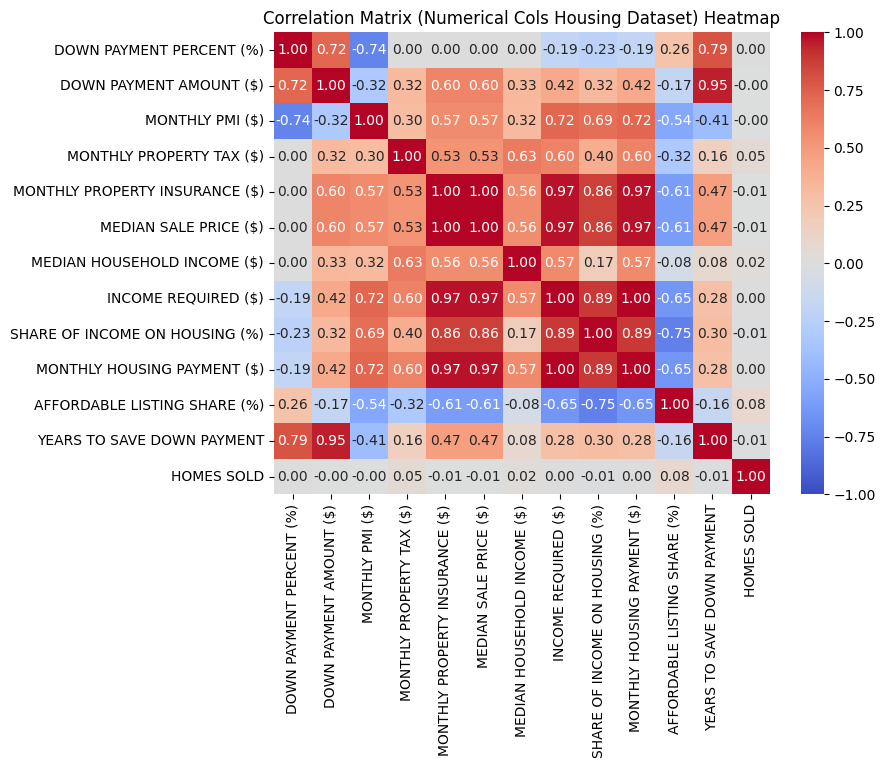

In [73]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrixNumericalCols,
    annot=True,  # Display numbers in each cell
    cmap="coolwarm",  # Diverging color scale
    center=0,  # Center color map at zero
    fmt=".2f",  # Format values to two decimals
    vmin=-1,
    vmax=1,
)

plt.title("Correlation Matrix (Numerical Cols Housing Dataset) Heatmap")
plt.show()

**Affordable = 0 (not affordable) vs Affordable = 1 (affordable) Class Imbalance Check**

In [76]:
UpdatedCombinedProperty_df[["SHARE OF INCOME ON HOUSING (%) Prop","affordable"]]

,SHARE OF INCOME ON HOUSING (%) Prop,affordable
0,0.3152,0.0
1,0.3156,0.0
2,0.3069,0.0
3,0.3011,0.0
4,0.2886,1.0
...,...,...
43255,0.1736,1.0
43256,0.1700,1.0
43257,0.1718,1.0
43258,0.1648,1.0


In [77]:
UpdatedCombinedProperty_df['affordable'].value_counts(normalize=True)

affordable
1.0    0.633038
0.0    0.366962
Name: proportion, dtype: float64

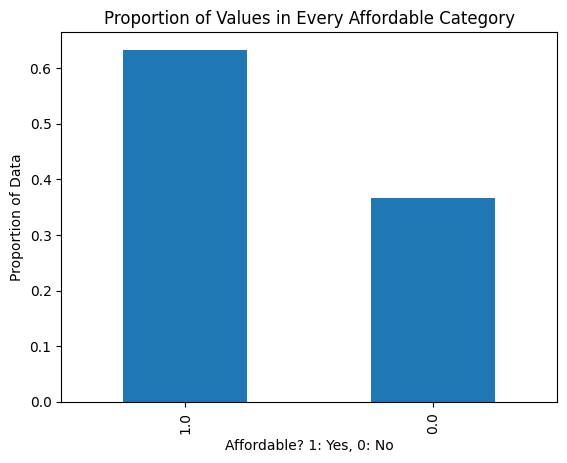

In [80]:
UpdatedCombinedProperty_df['affordable'].value_counts(normalize=True).plot(kind='bar')
plt.ylabel("Proportion of Data")
plt.xlabel("Affordable? 1: Yes, 0: No")
plt.title("Proportion of Values in Every Affordable Category")
plt.show()

**Findings: Affordable Categories**

* 63% of data is affordable = 1 categories

* 36.6% of data is non affordable (affordable = 0) categories

**Counting Number of Rows Every Region Identifier Takes Up in Model**

In [81]:
UpdatedCombinedProperty_df['Region Identifier'].value_counts()

Region Identifier
Southeast                10080
Midwest                  10080
Northeast                 9070
Mountain West             5040
Southwest                 4200
PNW                       1680
Non-Contiguous States     1665
Outside US                1445
Name: count, dtype: int64

**Identify Which Housing Asset Class Has Optimal Return on Investment**

In [5]:
UpdatedCombinedProperty_df['PERIOD BEGIN'] = pd.to_datetime(UpdatedCombinedProperty_df['PERIOD BEGIN'])

In [6]:
MedianYoYChance_ByProperty = UpdatedCombinedProperty_df.groupby(['PERIOD BEGIN', 'PROPERTY TYPE'])['MEDIAN SALE PRICE YOY (%)'].mean().unstack()

MedianYoYChance_ByProperty.sort_index()

PROPERTY TYPE,Condo/Co-op,Single Family,Starter Home,Townhouse
PERIOD BEGIN,,,,
2023-01-01,9.679412,1.925294,9.959412,6.345000
2023-02-01,2.892549,1.521373,10.235294,7.585510
2023-03-01,3.555098,0.680588,10.237059,2.175625
2023-04-01,2.269412,-0.839412,10.046078,1.944898
2023-05-01,4.435490,0.459804,9.326078,2.102653
2023-06-01,14.524706,1.187255,8.149020,2.557959
2023-07-01,7.674510,2.272353,6.763922,3.929796
2023-08-01,5.541961,4.385882,5.615490,4.895000
2023-09-01,7.023333,4.395882,4.866667,4.413333


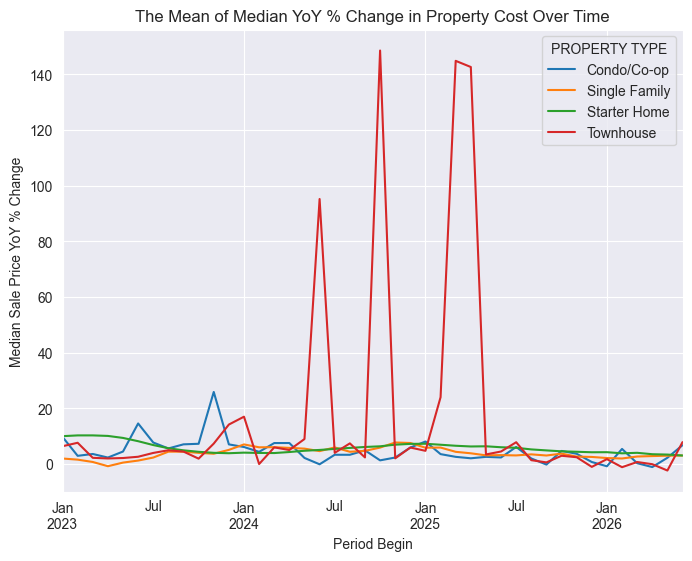

In [7]:
MedianYoYChance_ByProperty.plot(figsize=(8, 6))
plt.title("The Mean of Median YoY % Change in Property Cost Over Time")
plt.ylabel("Median Sale Price YoY % Change")
plt.xlabel("Period Begin")
plt.show()

In [8]:
print(UpdatedCombinedProperty_df['PERIOD BEGIN'].dtype)

datetime64[ns]


In [9]:
spike_rows = UpdatedCombinedProperty_df[(UpdatedCombinedProperty_df['PROPERTY TYPE'] == 'Townhouse') & (UpdatedCombinedProperty_df['MEDIAN SALE PRICE YOY (%)'] > 100)]

In [10]:
print(spike_rows.columns.tolist())

['FREQUENCY', 'PERIOD BEGIN', 'PERIOD END', 'REGION NAME', 'PROPERTY TYPE', 'INCOME GROUP', 'DOWN PAYMENT PERCENT (%)', 'INCOME REQUIRED ($)', 'INCOME REQUIRED YOY (%)', 'SHARE OF INCOME ON HOUSING (%)', 'SHARE OF INCOME ON HOUSING YOY (PPTS)', 'AFFORDABLE LISTING SHARE (%)', 'AFFORDABLE LISTING SHARE YOY (PPTS)', 'YEARS TO SAVE DOWN PAYMENT', 'YEARS TO SAVE DOWN PAYMENT YOY (%)', 'MONTHLY HOUSING PAYMENT ($)', 'MONTHLY MORTGAGE PAYMENT ($)', 'MONTHLY PROPERTY TAX ($)', 'MONTHLY PROPERTY INSURANCE ($)', 'MONTHLY PMI ($)', 'DOWN PAYMENT AMOUNT ($)', 'MEDIAN HOUSEHOLD INCOME ($)', 'MEDIAN SALE PRICE ($)', 'MEDIAN SALE PRICE YOY (%)', 'HOMES SOLD', 'HOMES SOLD YOY (%)', 'Year', 'Month', 'Month Name', 'Quarter', 'INCOME REQUIRED YOY (%) Prop', 'SHARE OF INCOME ON HOUSING (%) Prop', 'SHARE OF INCOME ON HOUSING YOY (PPTS) Prop', 'AFFORDABLE LISTING SHARE (%) Prop', 'AFFORDABLE LISTING SHARE YOY (PPTS) Prop', 'YEARS TO SAVE DOWN PAYMENT YOY (%) Prop', 'MEDIAN SALE PRICE YOY (%) Prop', 'HOMES 

In [11]:
spike_rows[["REGION NAME", "PERIOD BEGIN", "HOMES SOLD", "MEDIAN SALE PRICE YOY (%)"]]

,REGION NAME,PERIOD BEGIN,HOMES SOLD,MEDIAN SALE PRICE YOY (%)
12396,Connecticut,2024-05-01,1.0,211.88
12434,Connecticut,2024-05-01,1.0,211.88
12472,Connecticut,2024-05-01,1.0,211.88
12510,Connecticut,2024-05-01,1.0,211.88
12548,Connecticut,2024-05-01,1.0,211.88
...,...,...,...,...
19288,Rhode Island,2023-12-01,2.0,161.25
19328,Rhode Island,2023-12-01,2.0,161.25
19368,Rhode Island,2023-12-01,2.0,161.25
19408,Rhode Island,2023-12-01,2.0,161.25


In [101]:
louisiana_spikes = spike_rows[spike_rows['REGION NAME'] == 'Louisiana']
louisiana_spikes[['PERIOD BEGIN', 'HOMES SOLD', 'MEDIAN SALE PRICE YOY (%)', 'MEDIAN SALE PRICE ($)']]

,PERIOD BEGIN,HOMES SOLD,MEDIAN SALE PRICE YOY (%),MEDIAN SALE PRICE ($)
14675,2025-08-01,30.0,119.05,230000.0
14676,2025-07-01,43.0,236.28,190000.0
14679,2025-04-01,32.0,6717.39,196000.0
14680,2025-03-01,28.0,6683.11,162625.0
14681,2025-02-01,19.0,830.74,215000.0
14685,2024-10-01,35.0,6988.61,140000.0
14689,2024-06-01,49.0,4344.44,130000.0
14694,2024-01-01,27.0,337.45,125000.0
14717,2025-08-01,30.0,119.05,230000.0
14718,2025-07-01,43.0,236.28,190000.0


In [102]:
print(UpdatedCombinedProperty_df.duplicated().sum())


0


In [13]:
#10/8/26 Code:

townhouse_prices = UpdatedCombinedProperty_df[UpdatedCombinedProperty_df['PROPERTY TYPE'] == 'Townhouse']['MEDIAN SALE PRICE ($)']
townhouse_prices

10920    279300.0
10921    262500.0
10922    249900.0
10923    256803.0
10924    254500.0
           ...   
21625    350000.0
21626    322500.0
21627    309900.0
21628    398000.0
21629    342450.0
Name: MEDIAN SALE PRICE ($), Length: 10710, dtype: float64

In [14]:
townhouse_prices.describe()

count    1.018500e+04
mean     3.688103e+05
std      1.721110e+05
min      1.975000e+03
25%      2.799900e+05
50%      3.250000e+05
75%      3.999000e+05
max      1.465000e+06
Name: MEDIAN SALE PRICE ($), dtype: float64

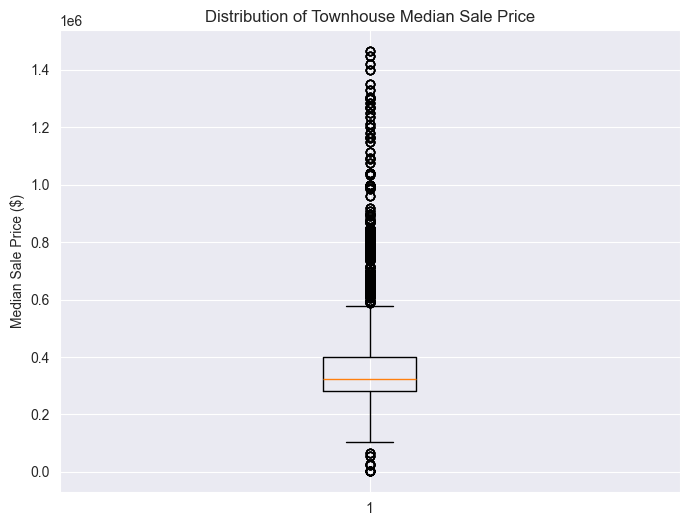

In [16]:
#boxplot of median townhome prices
plt.figure(figsize=(8,6))
plt.boxplot(townhouse_prices.dropna(), vert=True)
plt.title("Distribution of Townhouse Median Sale Price")
plt.ylabel("Median Sale Price ($)")
plt.show()

According to the boxplot above, the outlier values are below lower whisker price of $100,000. Thus, unusual median priced townhomes are below 100,000 dollars

In [23]:
# Checking Data on Lower Range Townhome Values:
all_low_th = UpdatedCombinedProperty_df[
    (UpdatedCombinedProperty_df['PROPERTY TYPE'] == 'Townhouse') &
    (UpdatedCombinedProperty_df['MEDIAN SALE PRICE ($)'] < 100000)
][['REGION NAME', 'PERIOD BEGIN', 'MEDIAN SALE PRICE ($)', 'HOMES SOLD']].drop_duplicates(
    subset=['REGION NAME', 'PERIOD BEGIN']
).sort_values('MEDIAN SALE PRICE ($)')

print(all_low_th)
print("\nStates involved:", all_low_th['REGION NAME'].unique())

      REGION NAME PERIOD BEGIN  MEDIAN SALE PRICE ($)  HOMES SOLD
14697   Louisiana   2023-10-01                 1975.0        35.0
14692   Louisiana   2024-03-01                 2398.0        40.0
14691   Louisiana   2024-04-01                 2875.0        45.0
14701   Louisiana   2023-06-01                 2925.0        47.0
14693   Louisiana   2024-02-01                23100.0        30.0
14706   Louisiana   2023-01-01                28575.0        18.0
14688   Louisiana   2024-07-01                56500.0        30.0
14700   Louisiana   2023-07-01                67000.0        39.0

States involved: ['Louisiana']


All states with extremely low median townhome sale prices are in Louisiana, the lowest loisiana median townhome sale price value being $1975. 

In [99]:
spike_rows['REGION NAME'].unique()

array(['Connecticut', 'Hawaii', 'Louisiana', 'Maine', 'Rhode Island'],
      dtype=object)

In [26]:

#Checking the raw unedited townhome dataset file to check that low townhome value was there
raw_townhouse = pd.read_csv("TownHouse_Redfin.csv")

raw_LA_check = raw_townhouse[
    (raw_townhouse['REGION NAME'] == 'Louisiana') &
    (raw_townhouse['PERIOD BEGIN'] == '2023-10-01')
]
print(raw_LA_check[['REGION NAME', 'PERIOD BEGIN', 'MEDIAN SALE PRICE ($)', 'HOMES SOLD']])

     REGION NAME PERIOD BEGIN  MEDIAN SALE PRICE ($)  HOMES SOLD
3777   Louisiana   2023-10-01                 1975.0        35.0
3819   Louisiana   2023-10-01                 1975.0        35.0
3861   Louisiana   2023-10-01                 1975.0        35.0
3903   Louisiana   2023-10-01                 1975.0        35.0
3945   Louisiana   2023-10-01                 1975.0        35.0


According to the code block above, the original Redfin townhome dataset had 1975 dollars as the median sale price - this is generally incorrect from the original dataset, as 1975 as a home sale price is very very low. 

In [29]:
unusuallyLowPriced_LA = (
    (UpdatedCombinedProperty_df["PROPERTY TYPE"]=='Townhouse') &
    (UpdatedCombinedProperty_df['MEDIAN SALE PRICE ($)'] < 100000) &
    (UpdatedCombinedProperty_df['REGION NAME'] == 'Louisiana')
)

print("Total amount of unsually low priced Louisiana rows: ", unusuallyLowPriced_LA.sum())

Total amount of unsually low priced Louisiana rows:  40


5 down payment prices x 8 odd priced louisiana homes = 40 unusually low priced Louisiana Rows

In [33]:
#Converting Lousiana Rows with Unusually Low Median Prices to NA
UpdatedCombinedProperty_df.loc[unusuallyLowPriced_LA, ['MEDIAN SALE PRICE ($)', 'MEDIAN SALE PRICE YOY (%)']] = pd.NA

In [37]:
bad_periods = UpdatedCombinedProperty_df.loc[unusuallyLowPriced_LA,'PERIOD BEGIN'].unique()

In [38]:
print(bad_periods)

<DatetimeArray>
['2024-07-01 00:00:00', '2024-04-01 00:00:00', '2024-03-01 00:00:00',
 '2024-02-01 00:00:00', '2023-10-01 00:00:00', '2023-07-01 00:00:00',
 '2023-06-01 00:00:00', '2023-01-01 00:00:00']
Length: 8, dtype: datetime64[ns]


In [40]:
print(sorted(bad_periods))

[Timestamp('2023-01-01 00:00:00'), Timestamp('2023-06-01 00:00:00'), Timestamp('2023-07-01 00:00:00'), Timestamp('2023-10-01 00:00:00'), Timestamp('2024-02-01 00:00:00'), Timestamp('2024-03-01 00:00:00'), Timestamp('2024-04-01 00:00:00'), Timestamp('2024-07-01 00:00:00')]


In [39]:
#identify date times that are a year away from the bad periods list above, as that will lead to high YOY% spikes too

echo_periods = pd.to_datetime(bad_periods) + pd.DateOffset(years=1)
print(sorted(echo_periods))

[Timestamp('2024-01-01 00:00:00'), Timestamp('2024-06-01 00:00:00'), Timestamp('2024-07-01 00:00:00'), Timestamp('2024-10-01 00:00:00'), Timestamp('2025-02-01 00:00:00'), Timestamp('2025-03-01 00:00:00'), Timestamp('2025-04-01 00:00:00'), Timestamp('2025-07-01 00:00:00')]


In [41]:
echoPeriod_data = ((UpdatedCombinedProperty_df['PROPERTY TYPE']=='Townhouse') & (UpdatedCombinedProperty_df['REGION NAME']=='Louisiana') & (UpdatedCombinedProperty_df['PERIOD BEGIN'].isin(echo_periods))
)

In [42]:
print("Number of Echo Rows Found: ", echoPeriod_data.sum())

Number of Echo Rows Found:  40


In [43]:
UpdatedCombinedProperty_df.loc[echoPeriod_data,'MEDIAN SALE PRICE YOY (%)'] = pd.NA

In [45]:
MedianYoYChance_ByPropertyMODIFIED = UpdatedCombinedProperty_df.groupby(['PERIOD BEGIN', 'PROPERTY TYPE'])['MEDIAN SALE PRICE YOY (%)'].mean().unstack()

MedianYoYChance_ByPropertyMODIFIED.sort_index()

PROPERTY TYPE,Condo/Co-op,Single Family,Starter Home,Townhouse
PERIOD BEGIN,,,,
2023-01-01,9.679412,1.925294,9.959412,8.140000
2023-02-01,2.892549,1.521373,10.235294,7.585510
2023-03-01,3.555098,0.680588,10.237059,2.175625
2023-04-01,2.269412,-0.839412,10.046078,1.944898
2023-05-01,4.435490,0.459804,9.326078,2.102653
2023-06-01,14.524706,1.187255,8.149020,4.647708
2023-07-01,7.674510,2.272353,6.763922,5.083542
2023-08-01,5.541961,4.385882,5.615490,4.895000
2023-09-01,7.023333,4.395882,4.866667,4.413333


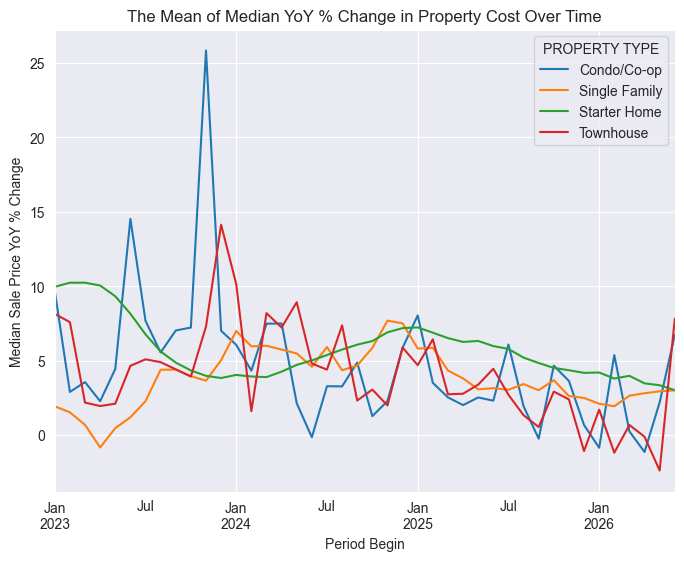

In [46]:
MedianYoYChance_ByPropertyMODIFIED.plot(figsize=(8, 6))
plt.title("The Mean of Median YoY % Change in Property Cost Over Time")
plt.ylabel("Median Sale Price YoY % Change")
plt.xlabel("Period Begin")
plt.show()

In [47]:
condo_prices = UpdatedCombinedProperty_df[UpdatedCombinedProperty_df['PROPERTY TYPE']=='Condo/Co-op']['MEDIAN SALE PRICE ($)']
print(condo_prices.describe())

count    1.071000e+04
mean     3.231943e+05
std      1.594686e+05
min      8.525000e+04
25%      2.349000e+05
50%      2.860000e+05
75%      3.850000e+05
max      3.322500e+06
Name: MEDIAN SALE PRICE ($), dtype: float64


In [48]:
print(condo_prices[condo_prices < 150000].sort_values())

32020     85250.0
31936     85250.0
31978     85250.0
32104     85250.0
32062     85250.0
           ...   
29325    148500.0
29283    148500.0
25485    148500.0
25611    148500.0
25527    148500.0
Name: MEDIAN SALE PRICE ($), Length: 280, dtype: float64


In [49]:
recent_townhouse = UpdatedCombinedProperty_df[
    (UpdatedCombinedProperty_df['PROPERTY TYPE']=='Townhouse') &
    (UpdatedCombinedProperty_df['PERIOD BEGIN'] >= '2025-10-01')
][['REGION NAME','PERIOD BEGIN','MEDIAN SALE PRICE ($)','MEDIAN SALE PRICE YOY (%)','HOMES SOLD']].sort_values('MEDIAN SALE PRICE YOY (%)')
print(recent_townhouse.head(10))

       REGION NAME PERIOD BEGIN  MEDIAN SALE PRICE ($)  \
12532  Connecticut   2025-12-01               229950.0   
12494  Connecticut   2025-12-01               229950.0   
12418  Connecticut   2025-12-01               229950.0   
12380  Connecticut   2025-12-01               229950.0   
12456  Connecticut   2025-12-01               229950.0   
13364       Hawaii   2026-05-01               755000.0   
13322       Hawaii   2026-05-01               755000.0   
13280       Hawaii   2026-05-01               755000.0   
13238       Hawaii   2026-05-01               755000.0   
13196       Hawaii   2026-05-01               755000.0   

       MEDIAN SALE PRICE YOY (%)  HOMES SOLD  
12532                     -57.63         2.0  
12494                     -57.63         2.0  
12418                     -57.63         2.0  
12380                     -57.63         2.0  
12456                     -57.63         2.0  
13364                     -43.23         9.0  
13322                     -43.23

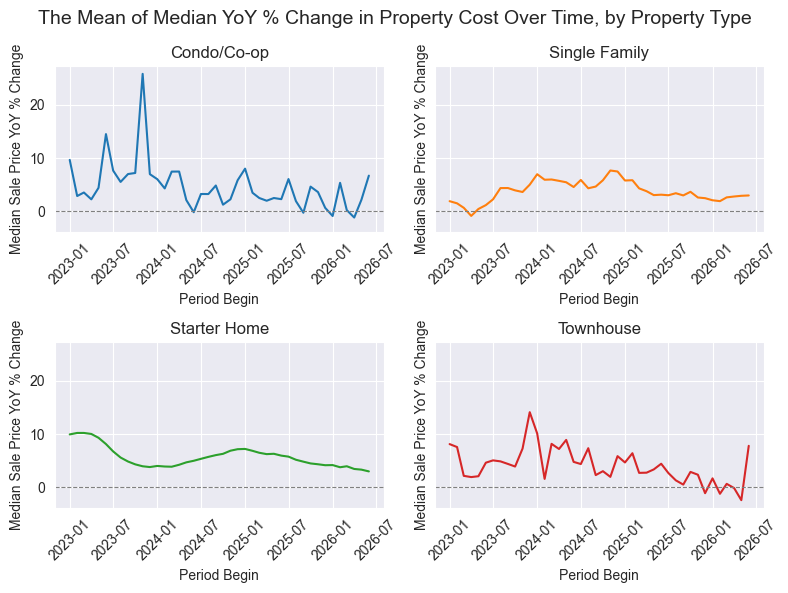

In [53]:
fig, axes = plt.subplots(2, 2, figsize=(8,6), sharey=True, sharex=True)

property_types = MedianYoYChance_ByPropertyMODIFIED.columns
axes = axes.flatten()

for i, prop_type in enumerate(property_types):
    axes[i].plot(MedianYoYChance_ByPropertyMODIFIED.index,
                 MedianYoYChance_ByPropertyMODIFIED[prop_type],
                 color=f'C{i}')
    axes[i].set_title(prop_type)
    axes[i].set_xlabel("Period Begin")
    axes[i].set_ylabel("Median Sale Price YoY % Change")
    axes[i].axhline(0, color='gray', linewidth=0.8, linestyle='--')
    axes[i].tick_params(axis='x', labelbottom=True, rotation=45)

fig.suptitle("The Mean of Median YoY % Change in Property Cost Over Time, by Property Type", fontsize=14)
plt.tight_layout()
plt.show()

In [55]:
propertyType_roi_summary = UpdatedCombinedProperty_df.groupby("PROPERTY TYPE")['MEDIAN SALE PRICE YOY (%)'].agg(['mean','median','std'])

propertyType_roi_summary

,mean,median,std
PROPERTY TYPE,,,
Condo/Co-op,4.665677,2.50,29.639935
Single Family,3.786438,3.72,4.904694
Starter Home,5.727656,5.35,4.805431
Townhouse,4.094845,2.45,17.731954


**Seasonality Ranking**


Finding the best season to buy each property type

In [58]:
UpdatedCombinedProperty_df.columns

Index(['FREQUENCY', 'PERIOD BEGIN', 'PERIOD END', 'REGION NAME',
       'PROPERTY TYPE', 'INCOME GROUP', 'DOWN PAYMENT PERCENT (%)',
       'INCOME REQUIRED ($)', 'INCOME REQUIRED YOY (%)',
       'SHARE OF INCOME ON HOUSING (%)',
       'SHARE OF INCOME ON HOUSING YOY (PPTS)', 'AFFORDABLE LISTING SHARE (%)',
       'AFFORDABLE LISTING SHARE YOY (PPTS)', 'YEARS TO SAVE DOWN PAYMENT',
       'YEARS TO SAVE DOWN PAYMENT YOY (%)', 'MONTHLY HOUSING PAYMENT ($)',
       'MONTHLY MORTGAGE PAYMENT ($)', 'MONTHLY PROPERTY TAX ($)',
       'MONTHLY PROPERTY INSURANCE ($)', 'MONTHLY PMI ($)',
       'DOWN PAYMENT AMOUNT ($)', 'MEDIAN HOUSEHOLD INCOME ($)',
       'MEDIAN SALE PRICE ($)', 'MEDIAN SALE PRICE YOY (%)', 'HOMES SOLD',
       'HOMES SOLD YOY (%)', 'Year', 'Month', 'Month Name', 'Quarter',
       'INCOME REQUIRED YOY (%) Prop', 'SHARE OF INCOME ON HOUSING (%) Prop',
       'SHARE OF INCOME ON HOUSING YOY (PPTS) Prop',
       'AFFORDABLE LISTING SHARE (%) Prop',
       'AFFORDABLE LISTI

In [59]:
SeasonAndPropertyType_avgAffordListingShare = UpdatedCombinedProperty_df.groupby(['Season', 'PROPERTY TYPE']).agg(avg_affordableListingSharePercent = ('AFFORDABLE LISTING SHARE (%)', 'mean'))

In [60]:
SeasonAndPropertyType_avgAffordListingShare

avg_affordableListingSharePercent
Season PROPERTY TYPE                                   
Fall   Condo/Co-op                            53.107922
       Single Family                          37.088331
       Starter Home                           80.448902
       Townhouse                              42.509175
Spring Condo/Co-op                            54.514088
       Single Family                          37.729866
       Starter Home                           82.419768
       Townhouse                              44.071214
Summer Condo/Co-op                            53.062871
       Single Family                          35.892125
       Starter Home                           80.731149
       Townhouse                              42.470016
Winter Condo/Co-op                            55.158963
       Single Family                          40.558998
       Starter Home                           83.323544
       Townhouse                              46.075603

In [61]:
SeasonandPropertyTypeGrouped_df = UpdatedCombinedProperty_df.groupby(["Season", "PROPERTY TYPE"])["AFFORDABLE LISTING SHARE (%)"].mean()

In [62]:
SeasonandPropertyTypeGrouped_df

Season  PROPERTY TYPE
Fall    Condo/Co-op      53.107922
        Single Family    37.088331
        Starter Home     80.448902
        Townhouse        42.509175
Spring  Condo/Co-op      54.514088
        Single Family    37.729866
        Starter Home     82.419768
        Townhouse        44.071214
Summer  Condo/Co-op      53.062871
        Single Family    35.892125
        Starter Home     80.731149
        Townhouse        42.470016
Winter  Condo/Co-op      55.158963
        Single Family    40.558998
        Starter Home     83.323544
        Townhouse        46.075603
Name: AFFORDABLE LISTING SHARE (%), dtype: float64

In [63]:
#creating the seasonality bar plot:

SeasonAndProperty_Data = SeasonandPropertyTypeGrouped_df.unstack()

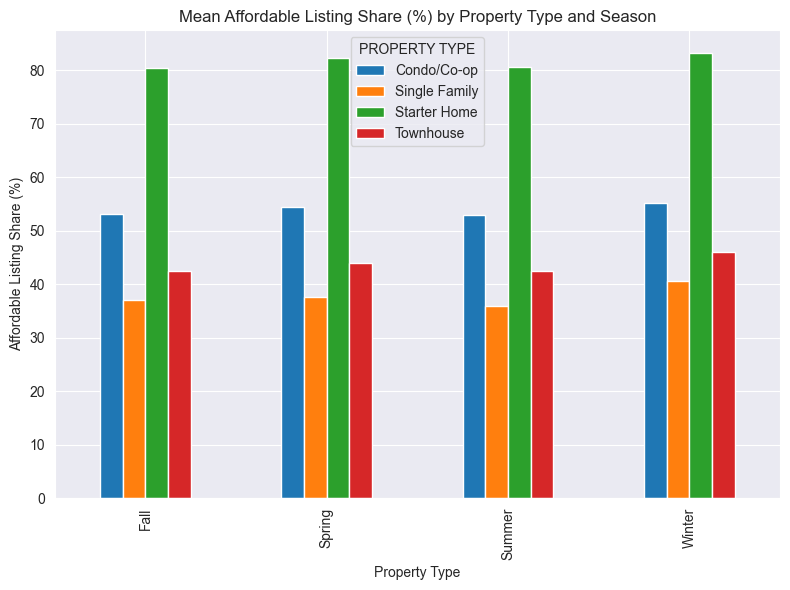

In [64]:
#creating the seasonality bar plot:
SeasonAndProperty_Data.plot(kind="bar",figsize=(8,6))

plt.title("Mean Affordable Listing Share (%) by Property Type and Season")
plt.xlabel("Property Type")
plt.ylabel("Affordable Listing Share (%)")
plt.tight_layout()
plt.show()

In [65]:
MonthandPropertyTypeGrouped_df = UpdatedCombinedProperty_df.groupby(["Month", "PROPERTY TYPE"])["AFFORDABLE LISTING SHARE (%)"].mean()

In [66]:
MonthandPropertyTypeGrouped_df

Month  PROPERTY TYPE
1      Condo/Co-op      55.628059
       Single Family    41.635559
       Starter Home     84.151451
       Townhouse        46.988380
2      Condo/Co-op      55.449922
       Single Family    40.773441
       Starter Home     83.886284
       Townhouse        46.528452
3      Condo/Co-op      54.973990
       Single Family    39.243755
       Starter Home     83.159637
       Townhouse        44.596707
4      Condo/Co-op      54.531422
       Single Family    37.651049
       Starter Home     82.471196
       Townhouse        44.150550
5      Condo/Co-op      54.036853
       Single Family    36.294794
       Starter Home     81.628471
       Townhouse        43.471640
6      Condo/Co-op      53.678039
       Single Family    35.882578
       Starter Home     81.194343
       Townhouse        43.264149
7      Condo/Co-op      52.230013
       Single Family    35.354536
       Starter Home     80.167059
       Townhouse        41.145987
8      Condo/Co-op      53.

In [69]:
MonthAndProperty_Data = MonthandPropertyTypeGrouped_df.unstack()


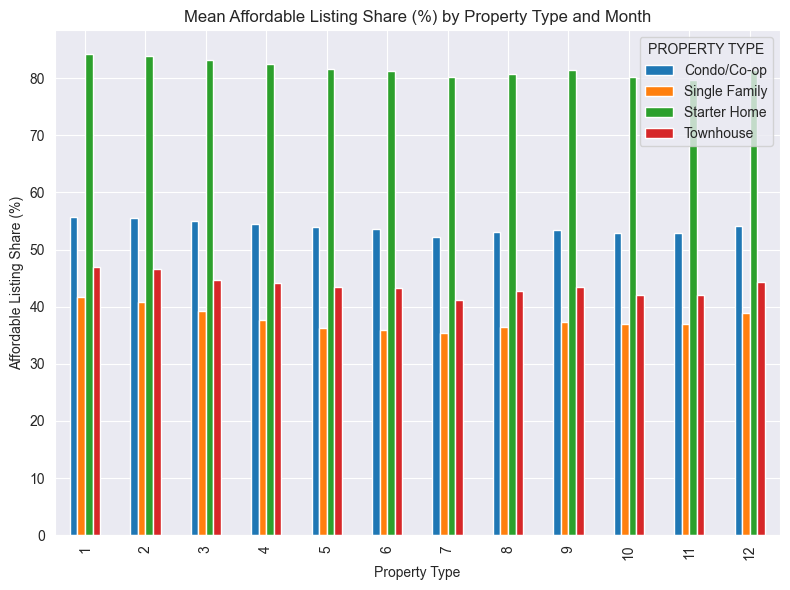

In [70]:
#creating the monthly mean affordable listing share % bar plot:
MonthAndProperty_Data.plot(kind="bar",figsize=(8,6))

plt.title("Mean Affordable Listing Share (%) by Property Type and Month")
plt.xlabel("Property Type")
plt.ylabel("Affordable Listing Share (%)")
plt.tight_layout()
plt.show()

In [71]:
SeasonandPropertyTypeGrouped_std = UpdatedCombinedProperty_df.groupby(["Season", "PROPERTY TYPE"])["AFFORDABLE LISTING SHARE (%)"].std()
print(SeasonandPropertyTypeGrouped_std)

Season  PROPERTY TYPE
Fall    Condo/Co-op      19.657629
        Single Family    16.154618
        Starter Home     22.802174
        Townhouse        20.083226
Spring  Condo/Co-op      19.180523
        Single Family    15.824262
        Starter Home     21.713893
        Townhouse        20.588894
Summer  Condo/Co-op      19.183076
        Single Family    15.609631
        Starter Home     22.644266
        Townhouse        20.371672
Winter  Condo/Co-op      19.298881
        Single Family    16.345726
        Starter Home     21.048384
        Townhouse        20.537989
Name: AFFORDABLE LISTING SHARE (%), dtype: float64


**Which states are becoming more affordable over time? Which states are becoming less affordable over time?**

In [97]:
shareIncomeHousing_byRegionAndProperty = UpdatedCombinedProperty_df.groupby(['REGION NAME', 'PROPERTY TYPE']).agg(
    **{
        'AVG Share of Income on Housing YOY (PPTS)' : ('SHARE OF INCOME ON HOUSING YOY (PPTS)','mean'),
        'AVG Number of Homes Sold' : ('HOMES SOLD','mean')
    } #claude assisted with renaming columns syntax
)


In [98]:
shareIncomeHousing_byRegionAndProperty_sorted = shareIncomeHousing_byRegionAndProperty.sort_values(by='AVG Share of Income on Housing YOY (PPTS)')

In [99]:
shareIncomeHousing_byRegionAndProperty_sorted.head(10)


,,AVG Share of Income on Housing YOY (PPTS),AVG Number of Homes Sold
REGION NAME,PROPERTY TYPE,,
Connecticut,Townhouse,-6.669500,1.391304
Idaho,Townhouse,-1.076048,90.404762
Oregon,Townhouse,-1.008476,188.500000
Florida,Condo/Co-op,-0.958381,5034.666667
Washington,Townhouse,-0.951524,431.571429
Utah,Condo/Co-op,-0.878714,287.619048
Oregon,Condo/Co-op,-0.876714,267.190476
Idaho,Single Family,-0.741048,2174.047619
Utah,Townhouse,-0.736000,528.857143


In [100]:
shareIncomeHousing_byRegionAndProperty_sorted.tail(14)


,,AVG Share of Income on Housing YOY (PPTS),AVG Number of Homes Sold
REGION NAME,PROPERTY TYPE,,
New Jersey,Single Family,1.516095,5338.261905
Maine,Starter Home,1.536333,784.428571
Mississippi,Townhouse,1.541143,47.190476
Kansas,Condo/Co-op,1.593381,31.500000
West Virginia,Starter Home,1.604524,969.261905
Kansas,Townhouse,1.614952,95.238095
Vermont,Townhouse,2.047429,44.642857
Louisiana,Townhouse,2.149810,33.571429
Mississippi,Condo/Co-op,2.709238,50.285714


In [78]:
#Checking the Number of Null Rows for Alaska:

alaska_subset = UpdatedCombinedProperty_df[
    (UpdatedCombinedProperty_df['REGION NAME']=='Alaska') & (UpdatedCombinedProperty_df['PROPERTY TYPE'] == 'Townhouse')
]['SHARE OF INCOME ON HOUSING YOY (PPTS)']

In [79]:
print(alaska_subset)

11130   NaN
11131   NaN
11132   NaN
11133   NaN
11134   NaN
         ..
11320   NaN
11321   NaN
11322   NaN
11323   NaN
11324   NaN
Name: SHARE OF INCOME ON HOUSING YOY (PPTS), Length: 195, dtype: float64


In [80]:
#checking the total number of Alaska Rows and NA Alaska Rows
totalAlaskaRows = len(alaska_subset)
num_Alaska_NA = alaska_subset.isna().sum()
num_Alaska_NotNA = alaska_subset.notna().sum()

print("total alaska rows: ", totalAlaskaRows)
print("total NA alaska rows: ", num_Alaska_NA)
print("total not NA alaska rows: ", num_Alaska_NotNA)

total alaska rows:  195
total NA alaska rows:  195
total not NA alaska rows:  0


In [81]:
connecticut_group = UpdatedCombinedProperty_df[
    (UpdatedCombinedProperty_df['REGION NAME']=='Connecticut') & (UpdatedCombinedProperty_df['PROPERTY TYPE'] == 'Townhouse')
]['SHARE OF INCOME ON HOUSING YOY (PPTS)']

In [83]:
len(connecticut_group)

190

In [84]:
print(connecticut_group.isna().sum())

130


**Analyzing Competition Vs. Affordability**

Are affordable months less or more competitive (more affordable homes in a month, more competition, more homes sold?) or (more affordable homes in a month, less competition thus less homes sold - makes a great customer recommendation on which months to look into a home)


In [101]:
UpdatedCombinedProperty_df.columns

Index(['FREQUENCY', 'PERIOD BEGIN', 'PERIOD END', 'REGION NAME',
       'PROPERTY TYPE', 'INCOME GROUP', 'DOWN PAYMENT PERCENT (%)',
       'INCOME REQUIRED ($)', 'INCOME REQUIRED YOY (%)',
       'SHARE OF INCOME ON HOUSING (%)',
       'SHARE OF INCOME ON HOUSING YOY (PPTS)', 'AFFORDABLE LISTING SHARE (%)',
       'AFFORDABLE LISTING SHARE YOY (PPTS)', 'YEARS TO SAVE DOWN PAYMENT',
       'YEARS TO SAVE DOWN PAYMENT YOY (%)', 'MONTHLY HOUSING PAYMENT ($)',
       'MONTHLY MORTGAGE PAYMENT ($)', 'MONTHLY PROPERTY TAX ($)',
       'MONTHLY PROPERTY INSURANCE ($)', 'MONTHLY PMI ($)',
       'DOWN PAYMENT AMOUNT ($)', 'MEDIAN HOUSEHOLD INCOME ($)',
       'MEDIAN SALE PRICE ($)', 'MEDIAN SALE PRICE YOY (%)', 'HOMES SOLD',
       'HOMES SOLD YOY (%)', 'Year', 'Month', 'Month Name', 'Quarter',
       'INCOME REQUIRED YOY (%) Prop', 'SHARE OF INCOME ON HOUSING (%) Prop',
       'SHARE OF INCOME ON HOUSING YOY (PPTS) Prop',
       'AFFORDABLE LISTING SHARE (%) Prop',
       'AFFORDABLE LISTI

In [102]:
avgNumHomesSoldAndAffordableListingShare_byMonth_df = UpdatedCombinedProperty_df.groupby(['Month Name']).agg(
    **{
        "Average Number of Homes Sold": ("HOMES SOLD","mean"),
        "Average Affordable Listing Share %" : ("AFFORDABLE LISTING SHARE (%)","mean")
    }
)

In [103]:
avgNumHomesSoldAndAffordableListingShare_byMonth_df

,Average Number of Homes Sold,Average Affordable Listing Share %
Month Name,,
April,2733.770756,54.753027
August,2992.315702,53.267551
December,2557.608553,54.728916
February,2222.085714,56.721985
January,2130.348259,57.150677
July,3004.088040,52.260721
June,3104.154703,53.542566
March,2561.774595,55.574240
May,3038.315136,53.909103


In [108]:
#checking correlation between Average Number of Homes Sold and Average Affordable Listing Share (%)
corrAvgHomesSoldAndAffordListShare_monthly = avgNumHomesSoldAndAffordableListingShare_byMonth_df['Average Number of Homes Sold'].corr(avgNumHomesSoldAndAffordableListingShare_byMonth_df['Average Affordable Listing Share %'])

In [109]:
print(corrAvgHomesSoldAndAffordListShare_monthly)

-0.8071829155030984


<Axes: xlabel='Average Number of Homes Sold', ylabel='Average Affordable Listing Share %'>

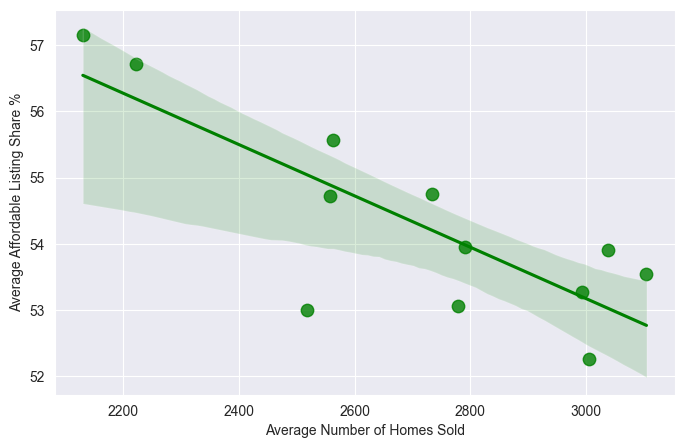

In [112]:
plt.figure(figsize=(8, 5))
sns.regplot(
    data=avgNumHomesSoldAndAffordableListingShare_byMonth_df,
    x='Average Number of Homes Sold',
    y='Average Affordable Listing Share %',
    color='green',
    marker='o',
    scatter_kws={'s': 80}
)

In [113]:
avgNumHomesAndAffordListingShareplot_df = avgNumHomesSoldAndAffordableListingShare_byMonth_df.reset_index()

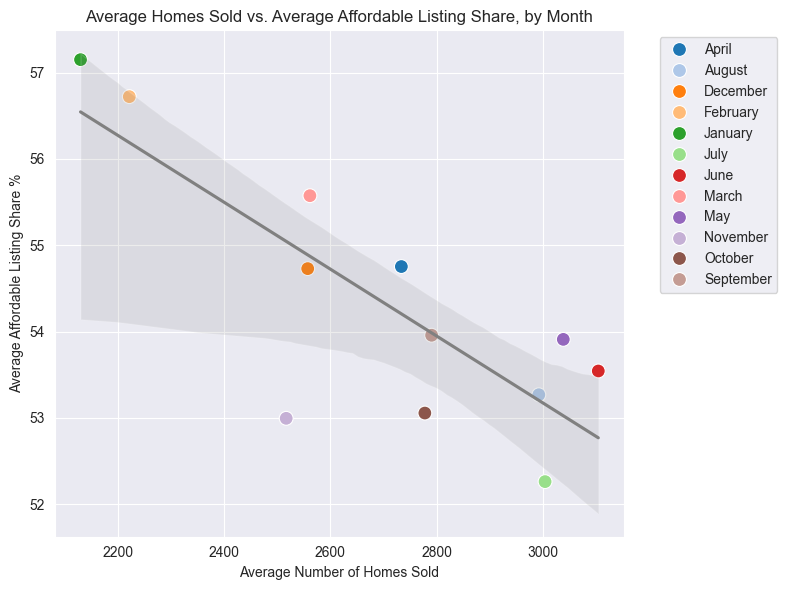

In [115]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=avgNumHomesAndAffordListingShareplot_df,
    x='Average Number of Homes Sold',
    y='Average Affordable Listing Share %',
    hue='Month Name',
    palette='tab20',
    s=100
)


sns.regplot(
    data=avgNumHomesAndAffordListingShareplot_df,
    x='Average Number of Homes Sold',
    y='Average Affordable Listing Share %',
    scatter=False,
    color='gray',
    line_kws={'linestyle': '-'}
)

plt.title("Average Homes Sold vs. Average Affordable Listing Share, by Month")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

National Level:

Correlation between Average Number of Homes Sold (Nationally) and Average Affordable Listing Share % (Nationally) going month by month is -0.807, which is strong. As Average Number of Homes Sold increases, the Average Affordable Listing Share % decreases.

Scatterplot Interp: As average number of homes sold increases, the average affordable listing share(%) is lower. This means that more homes are getting sold on average during times when the percentage of average affordable listing shares is low. So maybe during the months of January and February, a higher Average Affordable Listing Share (%) and less homes being sold means that there are more affordable listings available and less people are buying homes. Thus, January and February are ideals months to look at homes in the market and purchase them. On the other hand, during months of July and August, more homes are getting sold but the proportion of affordable listings available is lower, indicating that there is more competition in those summer months.

In [107]:
#checking correlation between Average Number of Homes Sold and Average Affordable Listing Share (%)
UpdatedCombinedProperty_df['HOMES SOLD'].corr(UpdatedCombinedProperty_df['AFFORDABLE LISTING SHARE (%)'])

np.float64(0.08190842645234375)

Correlation between HOMES SOLD for every period begin for every state and AFFORDABLE LISTING SHARE (%) for every period begin for every state is 0.08. HOMES SOLD and AFFORDABLE LISTING SHARE (%) have a weak correlation on raw data.

Overall Conclusion: Maybe the correlation between HOMES SOLD and AFFORDABLE LISTING SHARE (%) from a general, national perspective is seasonal.

In [5]:
print(UpdatedCombinedProperty_df.shape)
print(UpdatedCombinedProperty_df['PERIOD BEGIN'].dtype)
print(UpdatedCombinedProperty_df['PERIOD BEGIN'].max())
print(UpdatedCombinedProperty_df['REGION NAME'].unique())

(43260, 43)
object
9/1/2025
['Alabama' 'Alaska' 'Arizona' 'Arkansas' 'California' 'Colorado'
 'Columbia' 'Connecticut' 'Delaware' 'Florida' 'Georgia' 'Hawaii' 'Idaho'
 'Illinois' 'Indiana' 'Iowa' 'Kansas' 'Kentucky' 'Louisiana' 'Maine'
 'Maryland' 'Massachusetts' 'Michigan' 'Minnesota' 'Mississippi'
 'Missouri' 'Montana' 'Nebraska' 'Nevada' 'New Hampshire' 'New Jersey'
 'New Mexico' 'New York' 'North Carolina' 'North Dakota' 'Ohio' 'Oklahoma'
 'Oregon' 'Pennsylvania' 'Puerto Rico' 'Rhode Island' 'South Carolina'
 'South Dakota' 'Tennessee' 'Texas' 'Utah' 'Vermont' 'Virginia'
 'Washington' 'West Virginia' 'Wisconsin' 'Wyoming']


In [6]:
# If you have a cell earlier in this notebook that does pd.read_csv(...), check what path it used
# Also check if a more complete file exists
import os
print(os.listdir())  # lists files in your current working directory - look for your saved cleaned CSV

['.git', '.idea', 'combinedPropertyDataset.csv', 'Condo_cleanedDF.csv', 'MergedDataSetCode.ipynb', 'redfin_affordability_monthly_all_states_starter_home_homeowner_2023_Jan_to_2026_Jun.csv', 'redfin_affordability_starter_home_cleaned_test.csv', 'Redfin_Affordability_Starter_Home_Cleaning_Code.ipynb', 'SingleFamilyDatasetCleaning.ipynb', 'SingleFamily_cleanedDF.csv', 'SingleFamily_Redfin.csv', 'single_family_clean.csv', 'StarterHome_cleanedDF.csv', 'TaraEDA.ipynb', 'TownhouseDatasetCleaning.ipynb', 'Townhouse_cleanedDF.csv', 'TownHouse_Redfin.csv', 'UpdatedCombinedPropertyDataset.csv']


In [7]:


UpdatedCombinedProperty_df = pd.read_csv('UpdatedCombinedPropertyDataset.csv')

# Re-apply the datetime conversion, since CSV round-trips lose dtype
UpdatedCombinedProperty_df['PERIOD BEGIN'] = pd.to_datetime(UpdatedCombinedProperty_df['PERIOD BEGIN'])
UpdatedCombinedProperty_df['PERIOD END'] = pd.to_datetime(UpdatedCombinedProperty_df['PERIOD END'])

print(UpdatedCombinedProperty_df.shape)
print(UpdatedCombinedProperty_df['PERIOD BEGIN'].dtype)
print(UpdatedCombinedProperty_df['PERIOD BEGIN'].max())

(43260, 43)
datetime64[ns]
2026-06-01 00:00:00


In [8]:
test = UpdatedCombinedProperty_df[
    (UpdatedCombinedProperty_df['REGION NAME']=='Louisiana') &
    (UpdatedCombinedProperty_df['PROPERTY TYPE']=='Townhouse') &
    (UpdatedCombinedProperty_df['PERIOD BEGIN']=='2023-10-01')
][['MEDIAN SALE PRICE ($)','MEDIAN SALE PRICE YOY (%)']]
print(test)

       MEDIAN SALE PRICE ($)  MEDIAN SALE PRICE YOY (%)
14697                 1975.0                     -98.43
14739                 1975.0                     -98.43
14781                 1975.0                     -98.43
14823                 1975.0                     -98.43
14865                 1975.0                     -98.43


In [9]:
unusuallyLowPriced_LA = (
    (UpdatedCombinedProperty_df["PROPERTY TYPE"]=='Townhouse') &
    (UpdatedCombinedProperty_df['MEDIAN SALE PRICE ($)'] < 100000) &
    (UpdatedCombinedProperty_df['REGION NAME'] == 'Louisiana')
)

print("Total amount of unsually low priced Louisiana rows: ", unusuallyLowPriced_LA.sum())

Total amount of unsually low priced Louisiana rows:  40


In [10]:
UpdatedCombinedProperty_df.loc[unusuallyLowPriced_LA, ['MEDIAN SALE PRICE ($)', 'MEDIAN SALE PRICE YOY (%)']] = pd.NA


In [11]:
bad_periods = UpdatedCombinedProperty_df.loc[unusuallyLowPriced_LA,'PERIOD BEGIN'].unique()


In [12]:
print(bad_periods)

<DatetimeArray>
['2024-07-01 00:00:00', '2024-04-01 00:00:00', '2024-03-01 00:00:00',
 '2024-02-01 00:00:00', '2023-10-01 00:00:00', '2023-07-01 00:00:00',
 '2023-06-01 00:00:00', '2023-01-01 00:00:00']
Length: 8, dtype: datetime64[ns]


In [13]:
echo_periods = pd.to_datetime(bad_periods) + pd.DateOffset(years=1)
print(sorted(echo_periods))

[Timestamp('2024-01-01 00:00:00'), Timestamp('2024-06-01 00:00:00'), Timestamp('2024-07-01 00:00:00'), Timestamp('2024-10-01 00:00:00'), Timestamp('2025-02-01 00:00:00'), Timestamp('2025-03-01 00:00:00'), Timestamp('2025-04-01 00:00:00'), Timestamp('2025-07-01 00:00:00')]


In [14]:
echoPeriod_data = ((UpdatedCombinedProperty_df['PROPERTY TYPE']=='Townhouse') & (UpdatedCombinedProperty_df['REGION NAME']=='Louisiana') & (UpdatedCombinedProperty_df['PERIOD BEGIN'].isin(echo_periods))
)

In [15]:
print("Number of Echo Rows Found: ", echoPeriod_data.sum())

Number of Echo Rows Found:  40


In [16]:
UpdatedCombinedProperty_df.loc[echoPeriod_data,'MEDIAN SALE PRICE YOY (%)'] = pd.NA

In [17]:
test = UpdatedCombinedProperty_df[
    (UpdatedCombinedProperty_df['REGION NAME']=='Louisiana') &
    (UpdatedCombinedProperty_df['PROPERTY TYPE']=='Townhouse') &
    (UpdatedCombinedProperty_df['PERIOD BEGIN']=='2023-10-01')
][['MEDIAN SALE PRICE ($)','MEDIAN SALE PRICE YOY (%)']]
print(test)

       MEDIAN SALE PRICE ($)  MEDIAN SALE PRICE YOY (%)
14697                    NaN                        NaN
14739                    NaN                        NaN
14781                    NaN                        NaN
14823                    NaN                        NaN
14865                    NaN                        NaN


In [18]:
test_echo = UpdatedCombinedProperty_df[
    (UpdatedCombinedProperty_df['REGION NAME']=='Louisiana') &
    (UpdatedCombinedProperty_df['PROPERTY TYPE']=='Townhouse') &
    (UpdatedCombinedProperty_df['PERIOD BEGIN']=='2024-10-01')
][['MEDIAN SALE PRICE ($)','MEDIAN SALE PRICE YOY (%)']]
print(test_echo)

       MEDIAN SALE PRICE ($)  MEDIAN SALE PRICE YOY (%)
14685               140000.0                        NaN
14727               140000.0                        NaN
14769               140000.0                        NaN
14811               140000.0                        NaN
14853               140000.0                        NaN


In [23]:
UpdatedCombinedProperty_dfLAFixed = UpdatedCombinedProperty_df.copy()

In [24]:
test_LAFixed = UpdatedCombinedProperty_dfLAFixed[
    (UpdatedCombinedProperty_dfLAFixed['REGION NAME']=='Louisiana') &
    (UpdatedCombinedProperty_dfLAFixed['PROPERTY TYPE']=='Townhouse') &
    (UpdatedCombinedProperty_dfLAFixed['PERIOD BEGIN']=='2023-10-01')
][['MEDIAN SALE PRICE ($)','MEDIAN SALE PRICE YOY (%)']]
print(test_LAFixed)

       MEDIAN SALE PRICE ($)  MEDIAN SALE PRICE YOY (%)
14697                    NaN                        NaN
14739                    NaN                        NaN
14781                    NaN                        NaN
14823                    NaN                        NaN
14865                    NaN                        NaN


In [25]:
test_echoLAFixed = UpdatedCombinedProperty_dfLAFixed[
    (UpdatedCombinedProperty_dfLAFixed['REGION NAME']=='Louisiana') &
    (UpdatedCombinedProperty_dfLAFixed['PROPERTY TYPE']=='Townhouse') &
    (UpdatedCombinedProperty_dfLAFixed['PERIOD BEGIN']=='2024-10-01')
][['MEDIAN SALE PRICE ($)','MEDIAN SALE PRICE YOY (%)']]
print(test_echoLAFixed)

       MEDIAN SALE PRICE ($)  MEDIAN SALE PRICE YOY (%)
14685               140000.0                        NaN
14727               140000.0                        NaN
14769               140000.0                        NaN
14811               140000.0                        NaN
14853               140000.0                        NaN


In [26]:
#new dataset that excludes Louisiana rows where Median Sale Price is less than 100,000
UpdatedCombinedProperty_dfLAFixed.to_csv('UpdatedCombinedProperty_dfLAFixed.csv', index=False)

In [7]:
dataset_df = pd.read_csv("UpdatedCombinedPropertyDataset.csv")

In [8]:
dataset_df.head()

,FREQUENCY,PERIOD BEGIN,PERIOD END,REGION NAME,PROPERTY TYPE,INCOME GROUP,DOWN PAYMENT PERCENT (%),INCOME REQUIRED ($),INCOME REQUIRED YOY (%),SHARE OF INCOME ON HOUSING (%),...,AFFORDABLE LISTING SHARE (%) Prop,AFFORDABLE LISTING SHARE YOY (PPTS) Prop,YEARS TO SAVE DOWN PAYMENT YOY (%) Prop,MEDIAN SALE PRICE YOY (%) Prop,HOMES SOLD YOY (%) Prop,Season,Year-Month,Period Length (Days),affordable,Region Identifier
0,Monthly,6/1/2026,6/30/2026,Alabama,Single Family,Homeowner,3.5,90532.0,-1.49,31.52,...,0.4057,0.0287,-0.0276,0.0130,0.0832,Summer,2026-06,30,0.0,Southeast
1,Monthly,5/1/2026,5/31/2026,Alabama,Single Family,Homeowner,3.5,90652.0,-0.56,31.56,...,0.4212,0.0419,-0.0142,0.0269,0.0091,Spring,2026-05,31,0.0,Southeast
2,Monthly,4/1/2026,4/30/2026,Alabama,Single Family,Homeowner,3.5,88160.0,0.65,30.69,...,0.4302,0.0365,-0.0003,0.0413,0.0217,Spring,2026-04,30,0.0,Southeast
3,Monthly,3/1/2026,3/31/2026,Alabama,Single Family,Homeowner,3.5,86472.0,-1.26,30.11,...,0.4482,0.0405,-0.0133,0.0279,0.0641,Spring,2026-03,31,0.0,Southeast
4,Monthly,2/1/2026,2/28/2026,Alabama,Single Family,Homeowner,3.5,82901.0,-3.96,28.86,...,0.4824,0.0765,-0.0137,0.0274,0.0637,Winter,2026-02,28,1.0,Southeast


In [23]:
dataset_df['REGION NAME'].unique()

array(['Alabama', 'Alaska', 'Arizona', 'Arkansas', 'California',
       'Colorado', 'Columbia', 'Connecticut', 'Delaware', 'Florida',
       'Georgia', 'Hawaii', 'Idaho', 'Illinois', 'Indiana', 'Iowa',
       'Kansas', 'Kentucky', 'Louisiana', 'Maine', 'Maryland',
       'Massachusetts', 'Michigan', 'Minnesota', 'Mississippi',
       'Missouri', 'Montana', 'Nebraska', 'Nevada', 'New Hampshire',
       'New Jersey', 'New Mexico', 'New York', 'North Carolina',
       'North Dakota', 'Ohio', 'Oklahoma', 'Oregon', 'Pennsylvania',
       'Puerto Rico', 'Rhode Island', 'South Carolina', 'South Dakota',
       'Tennessee', 'Texas', 'Utah', 'Vermont', 'Virginia', 'Washington',
       'West Virginia', 'Wisconsin', 'Wyoming'], dtype=object)

In [9]:
Texas_df = dataset_df[dataset_df['REGION NAME'] == 'Texas']

In [10]:
Texas_df.head()

,FREQUENCY,PERIOD BEGIN,PERIOD END,REGION NAME,PROPERTY TYPE,INCOME GROUP,DOWN PAYMENT PERCENT (%),INCOME REQUIRED ($),INCOME REQUIRED YOY (%),SHARE OF INCOME ON HOUSING (%),...,AFFORDABLE LISTING SHARE (%) Prop,AFFORDABLE LISTING SHARE YOY (PPTS) Prop,YEARS TO SAVE DOWN PAYMENT YOY (%) Prop,MEDIAN SALE PRICE YOY (%) Prop,HOMES SOLD YOY (%) Prop,Season,Year-Month,Period Length (Days),affordable,Region Identifier
9240,Monthly,6/1/2026,6/30/2026,Texas,Single Family,Homeowner,3.5,115076.0,-2.88,31.52,...,0.4220,0.0600,-0.0438,-0.0040,0.0492,Summer,2026-06,30,0.0,Southwest
9241,Monthly,5/1/2026,5/31/2026,Texas,Single Family,Homeowner,3.5,113448.0,-2.86,31.07,...,0.4279,0.0657,-0.0399,0.0001,-0.0232,Spring,2026-05,31,0.0,Southwest
9242,Monthly,4/1/2026,4/30/2026,Texas,Single Family,Homeowner,3.5,110859.0,-3.02,30.37,...,0.4436,0.0729,-0.0400,0.0000,0.0367,Spring,2026-04,30,0.0,Southwest
9243,Monthly,3/1/2026,3/31/2026,Texas,Single Family,Homeowner,3.5,108611.0,-4.41,29.75,...,0.4643,0.0798,-0.0485,-0.0088,0.0352,Spring,2026-03,31,1.0,Southwest
9244,Monthly,2/1/2026,2/28/2026,Texas,Single Family,Homeowner,3.5,105282.0,-5.90,28.84,...,0.4867,0.0941,-0.0400,0.0000,-0.0428,Winter,2026-02,28,1.0,Southwest


In [11]:
Texas_df = Texas_df[Texas_df['PROPERTY TYPE'] == 'Single Family']

In [12]:
Texas_df['PROPERTY TYPE'].unique() #should only print 'single family'

array(['Single Family'], dtype=object)

In [13]:
Texas_df['REGION NAME'].unique()

array(['Texas'], dtype=object)

In [16]:
Texas_df['Year'].unique()


array([2026, 2025, 2024, 2023])

In [14]:
Texas_df['MEDIAN SALE PRICE ($)'].mean()

np.float64(339427.78571428574)

In [17]:
Cali_df = dataset_df[dataset_df['REGION NAME'] == 'California']

In [18]:
Cali_df = Cali_df[Cali_df['PROPERTY TYPE'] == 'Single Family']

In [19]:
Cali_df['REGION NAME'].unique()

array(['California'], dtype=object)

In [20]:
Cali_df['PROPERTY TYPE'].unique()

array(['Single Family'], dtype=object)

In [21]:
Cali_df['MEDIAN SALE PRICE ($)'].mean()

np.float64(748386.4761904762)

In [22]:
Cali_df['REGION NAME'].unique()

array(['California'], dtype=object)